
# Simulating the $\mathbb{Z}_2$-Higgs bunching crossover on four cavities

## Central claim

> **Four cavities and three transmons, driven only by $g1e0$ sidebands, can simulate the
> 1D $\mathbb{Z}_2$ lattice gauge theory of
> [arXiv:2503.03828](https://arxiv.org/abs/2503.03828) well enough to *see the bunching
> crossover*: an order parameter that collapses by an order of magnitude as $U$ is tuned
> through $U_c=3J^2/g$, while a second preparation that Gauss' law forbids to respond
> stays flat.**

Everything below is one argument for that sentence, in six steps.

| | question | answer | headline number |
|---|---|---|---|
| **1** | Is the crossover visible in the ideal model? | **yes, at 8 photons** | $\mathcal F$ collapses **12.7$\times$**; control **1.2$\times$** |
| **2** | Which synthesis reproduces it, and at what cost? | **symmetrized $W_{\rm sym}$** | $Jt=2$, 41&ndash;80 steps, 656&ndash;1280 pulses, 14&ndash;20 &micro;s |
| **3** | Does it survive Trotterization? | **yes** | **10.0$\times$** (41 steps), **12.2$\times$** (80 steps) |
| **4** | Does it survive decoherence? | **yes** | **5.6$\times$** raw, **8.0$\times$** post-selected |
| **5** | Where does the $U$ term come from, with no static cross-Kerr? | **a detuned sideband to a parked ancilla** | $U=2g_s^4/\Delta^3$, tunable, exactly zero when the pump is off |
| **6** | And if $U$ cannot be tuned at all? | **sweep $g$ instead &mdash; it is free** | the $g$-sweep and the $U$-sweep fall on one curve |

**The model.**

$$\hat H=-g\sum_{l}\hat Z_{l}-J\sum_{l}\left(\hat a_l^\dagger \hat X_{l}\hat a_{l+1}+\text{h.c.}\right)+\frac U2\sum_{i}\hat n_i^2$$

with matter (photons) on four cavities and the $\mathbb{Z}_2$ gauge field on three
transmons sitting on the links. A Hadamard on every gauge qubit maps this to what the
hardware natively speaks,

$$\tilde H=-g\sum_l \hat X_l\;-\;J\sum_l \hat Z_l\left(a_l^\dagger a_{l+1}+\text{h.c.}\right)\;+\;\frac U2\sum_i \hat n_i^2 ,$$

i.e. a single-qubit $X$ rotation on each transmon plus a **transmon-controlled cavity&ndash;cavity
beamsplitter** on each link. Only the second is hard, and it is exactly what a pair of
$g1e0$ sidebands makes as a group commutator.

**Operating point used throughout:** $g/J=8$, $N=8$ photons, so $U_c=3J^2/g=0.375\,J$.

**Only the $\{g,e\}$ doublet is ever driven.** The controlled beamsplitter is the group
commutator of two sidebands, and that identity needs only
$[\sigma_-,\sigma_+]=P_{\rm lower}-P_{\rm upper}$, which is true of any two-level ladder.
$W_{\rm sym}$, the synthesis actually used, needs no $\pi$ pulses either. So $|f\rangle$ is
never populated, never calibrated and never read out; it stays free as headroom, which is
what makes off-resonant leakage ($\sim(g_s\sqrt n/\alpha)^2\sim3\times10^{-4}$ at eight
photons) a margin rather than an error term.

---

### The five words this notebook keeps using

Every number below is one of these. They are defined here once and not redefined later.

| term | definition |
|---|---|
| **preparation** | the Fock state $\lvert n_0n_1n_2n_3\rangle$ the cavities are loaded with at $t=0$, together with the gauge-qubit state Gauss' law then forces. A Fock state has no number fluctuations, so **every run starts at $\mathcal F=0$**, whatever the preparation. $\mathcal F$ is made by the dynamics, not loaded. |
| **probe** | the preparation whose $\mathcal F$ is *allowed* to respond to $U$: $\lvert 2,2,2,2\rangle$. Even site parities $\Rightarrow$ electric energy $-3g$ $\Rightarrow$ pair hopping is resonant and the photons are free to bunch. |
| **control** | the preparation that is *forbidden* to respond, by Gauss' law: $\lvert 3,1,1,3\rangle$. Odd site parities $\Rightarrow$ $+g$ $\Rightarrow$ single hops cost $2g$ and pair hops are blocked. It is not a fitted background: it is a second experiment whose answer is known before it is run. |
| $\mathcal R$ (**contrast**) | of *one* preparation: $\mathcal R=\mathcal F(U{=}0)\,/\,\mathcal F(U{=}3U_c)$, both read at the same $Jt$. The absolute $\mathcal F$ depends on which state you loaded and carries no phase information; the ratio does. |
| **separation** | $\mathcal R_{\rm probe}/\mathcal R_{\rm control}$. This is the falsifiable number. Anything that fakes a collapse in the probe &mdash; photon loss, a drifting readout, a miscalibrated $U$ axis &mdash; fakes the same collapse in the control and cancels in the ratio. **Separation $\approx1$ means no crossover was seen**, no matter how impressive the probe curve looks on its own. |


---
## 0. Machinery

A **total-photon-truncated** basis $\{|q_0q_1q_2\rangle\otimes|n_0n_1n_2n_3\rangle:\sum_i
n_i\le N_{\rm cut}\}$, not a per-cavity Fock cutoff: the photon budget is shared and the
bunched states we care about pile many photons on one site.

Two truncations appear below and both matter:

* $N_{\rm cut}=8$ ($D=3960$) for anything driven by **ideal gates** — nothing can add a photon.
* $N_{\rm cut}=10$ ($D=8008$) for anything driven by **sidebands** — a pulse can transiently
  move an excitation out of a transmon and into a cavity, so the total photon number is not
  conserved during a pulse. Section 2 checks that the extra headroom changes nothing.

In [1]:
"""Z2-Higgs on 4 cavities + 3 transmons: exact, Trotter, Floquet and sideband schemes.

Conventions
-----------
Gauge qubit l (l = 0,1,2) sits on the link between cavity l and cavity l+1.
Level |0> = |g> (Z = +1), |1> = |e> (Z = -1).  sigma_+ = |e><g| = |1><0|.

Rotated-frame (Hadamard on every gauge qubit) Hamiltonian, which is the one the
hardware natively speaks:

    H = -g sum_l X_l  -  J sum_l Z_l (a_l^dag a_{l+1} + h.c.)  +  (U/2) sum_i n_i^2

Basis: |q_0 q_1 q_2> (x) |n_0 n_1 n_2 n_3> with sum_i n_i <= N_cut.
Full index = q * n_boson + b, so every operator is kron(qubit_op, boson_op).
"""

from itertools import product

import numpy as np
import scipy.linalg as sla
import scipy.sparse as sps
import scipy.sparse.linalg as spla

# ---------------------------------------------------------------- 2x2 blocks
I2 = np.eye(2, dtype=complex)
SX = np.array([[0, 1], [1, 0]], dtype=complex)
SY = np.array([[0, -1j], [1j, 0]], dtype=complex)
SZ = np.array([[1, 0], [0, -1]], dtype=complex)
SP = np.array([[0, 0], [1, 0]], dtype=complex)   # |e><g| = |1><0|
SM = SP.conj().T                                  # |g><e|


class Lattice:
    """Truncated Hilbert space and every operator built on it."""

    def __init__(self, L=4, N_cut=6):
        self.L, self.nq, self.N_cut = L, L - 1, N_cut

        # boson Fock states with a TOTAL photon budget (not a per-cavity cutoff)
        self.bs = [t for t in product(range(N_cut + 1), repeat=L) if sum(t) <= N_cut]
        self.bidx = {t: i for i, t in enumerate(self.bs)}
        self.nb = len(self.bs)
        self.dq = 2 ** self.nq
        self.D = self.dq * self.nb
        self.ntot = np.array([sum(t) for t in self.bs])          # per boson state

        # ---- boson operators (nb x nb), sparse
        self.a = [self._a(i) for i in range(L)]
        self.ad = [A.conj().T.tocsr() for A in self.a]
        self.nb_op = [(self.ad[i] @ self.a[i]).tocsr() for i in range(L)]

        # ---- full-space operators
        Iq, Ib = sps.identity(self.dq, format="csr"), sps.identity(self.nb, format="csr")
        self.Ib_sp, self.Iq_sp = Ib, Iq
        self.A = [sps.kron(Iq, self.a[i], "csr") for i in range(L)]
        self.Ad = [sps.kron(Iq, self.ad[i], "csr") for i in range(L)]
        self.N = [sps.kron(Iq, self.nb_op[i], "csr") for i in range(L)]
        self.Ntot = sum(self.N)

        self.X = [self._q(SX, l) for l in range(self.nq)]
        self.Y = [self._q(SY, l) for l in range(self.nq)]
        self.Z = [self._q(SZ, l) for l in range(self.nq)]
        self.Sp = [self._q(SP, l) for l in range(self.nq)]
        self.Sm = [self._q(SM, l) for l in range(self.nq)]

        # Beamsplitter quadrature on link l:  a_l^dag a_{l+1} + h.c.
        # Written as Ad[l]A[l+1] + Ad[l+1]A[l] on purpose: the algebraically equal
        # form A[l]Ad[l+1] raises the photon number first and is therefore
        # truncated at sum(n) = N_cut, which would make BS non-Hermitian here.
        self.BS = [(self.Ad[l] @ self.A[l + 1] + self.Ad[l + 1] @ self.A[l]).tocsr()
                   for l in range(self.nq)]
        # controlled hop  Z_l (a_l^dag a_{l+1} + h.c.)
        self.ZBS = [(self.Z[l] @ self.BS[l]).tocsr() for l in range(self.nq)]

        # photon parity (-1)^{n_i} in the boson space, then lifted
        self.par = [sps.kron(Iq, sps.diags(
            [(-1.0) ** t[i] for t in self.bs]).tocsr(), "csr") for i in range(L)]

        # Gauss operators, rotated frame:  G_i = X_{i-1} (-1)^{n_i} X_i
        self.G = []
        for i in range(L):
            op = self.par[i]
            if i - 1 >= 0:
                op = self.X[i - 1] @ op
            if i < self.nq:
                op = op @ self.X[i]
            self.G.append(op.tocsr())

        # index bookkeeping
        self.sector = {}                                   # n -> full-space indices
        for n in range(N_cut + 1):
            bsel = np.nonzero(self.ntot == n)[0]
            self.sector[n] = np.concatenate(
                [q * self.nb + bsel for q in range(self.dq)])

    # ------------------------------------------------------------------ build
    def _a(self, i):
        r, c, d = [], [], []
        for b, t in enumerate(self.bs):
            if t[i] > 0:
                u = list(t)
                u[i] -= 1
                r.append(self.bidx[tuple(u)])
                c.append(b)
                d.append(np.sqrt(t[i]))
        return sps.coo_matrix((d, (r, c)), shape=(self.nb, self.nb), dtype=complex).tocsr()

    def _q(self, m, l):
        """2x2 block `m` on qubit l, identity elsewhere, lifted to the full space."""
        out = np.array([[1.0 + 0j]])
        for k in range(self.nq):
            out = np.kron(out, m if k == l else I2)
        return sps.kron(sps.csr_matrix(out), self.Ib_sp, "csr")

    # ------------------------------------------------------------ Hamiltonian
    def H(self, g, J, U):
        """Rotated-frame Z2-Higgs Hamiltonian."""
        h = sps.csr_matrix((self.D, self.D), dtype=complex)
        for l in range(self.nq):
            h = h - g * self.X[l] - J * self.ZBS[l]
        for i in range(self.L):
            h = h + 0.5 * U * (self.N[i] @ self.N[i])
        return h.tocsr()

    # ------------------------------------------------------------ state prep
    def fock(self, occ, qubit_amp):
        """|qubit_amp> (x) |occ>;  qubit_amp is a length-2^nq complex vector."""
        v = np.zeros(self.D, dtype=complex)
        b = self.bidx[tuple(occ)]
        for q in range(self.dq):
            v[q * self.nb + b] = qubit_amp[q]
        return v / np.linalg.norm(v)

    def gauss_qubit_state(self, occ):
        """X-basis qubit amplitudes fixed by Gauss' law for the Fock state `occ`.

        G_i = +1 for every i forces  X_l = (-1)^{n_0 + ... + n_l}.
        """
        signs = [(-1) ** int(np.sum(occ[: l + 1])) for l in range(self.nq)]
        amp = np.array([1.0 + 0j])
        for s in signs:                       # |+> = (1,1)/sqrt2 , |-> = (1,-1)/sqrt2
            amp = np.kron(amp, np.array([1.0, s], dtype=complex) / np.sqrt(2))
        return amp

    def physical_state(self, occ):
        return self.fock(occ, self.gauss_qubit_state(occ))


# ==================================================================== metrics
def expect(op, v):
    return complex(np.vdot(v, op @ v)).real


def observables(lat, v):
    """Every number the comparison is judged on."""
    n = np.array([expect(lat.N[i], v) for i in range(lat.L)])
    n2 = np.array([expect(lat.N[i] @ lat.N[i], v) for i in range(lat.L)])
    var = n2 - n ** 2
    pair = []
    for l in range(lat.nq):
        P = lat.Ad[l] @ lat.Ad[l] @ lat.A[l + 1] @ lat.A[l + 1]
        pair.append(expect(P + P.conj().T, v))
    return {
        "n": n,
        "var": var,
        "F_bunch": float(var.mean()),                       # bunching order parameter
        "C2_nn": float(np.mean(pair)),                      # nearest-neighbour pairs
        "G": np.array([expect(lat.G[i], v) for i in range(lat.L)]),
        "Ntot": float(expect(lat.Ntot, v)),
        "parity": np.array([expect(lat.par[i], v) for i in range(lat.L)]),
    }


def fidelity(u, v):
    return float(abs(np.vdot(u, v)) ** 2)


# =============================================================== propagation
def expm_multiply_(H, t, v):
    return spla.expm_multiply(-1j * t * H, v)


def evolve_exact(H, v, ts):
    """Krylov time evolution, returns states at every t in `ts` (ts increasing)."""
    out, cur, t0 = [], v.copy(), 0.0
    for t in ts:
        dt = t - t0
        if dt > 0:
            cur = spla.expm_multiply(-1j * dt * H, cur)
        out.append(cur.copy())
        t0 = t
    return out


class Prop:
    """exp(-i H t) applied to vectors; dense-cached when it is cheap enough."""

    def __init__(self, H, t, dense_limit=0):
        self.H, self.t, self.U = H, t, None
        if H.shape[0] <= dense_limit:
            self.U = _expm_dense(H, t)

    def __call__(self, v):
        if self.U is not None:
            return self.U @ v
        return spla.expm_multiply(-1j * self.t * self.H, v)


def _expm_dense(H, t):
    return sla.expm(-1j * t * H.toarray())


# ==================================================== scheme 2 & 3: ideal gates
def ideal_layers(lat, g, J, U, dt, order=2):
    """Time-ordered [(name, propagator)] for one ideal-gate Trotter step.

    Layer LOC  : exp(+i g dt sum_l X_l) exp(-i (U/2) dt sum_i n_i^2)   (commuting)
    Layer B13  : links 0 and 2 (disjoint cavities -> simultaneous)
    Layer B2   : link 1
    """
    Hloc = -g * sum(lat.X) + 0.5 * U * sum(lat.N[i] @ lat.N[i] for i in range(lat.L))
    H13 = -J * (lat.ZBS[0] + lat.ZBS[2])
    H2 = -J * lat.ZBS[1]
    if order == 1:
        return [("LOC", Prop(Hloc, dt)), ("B13", Prop(H13, dt)), ("B2", Prop(H2, dt))]
    h = [("LOC", Prop(Hloc, dt / 2)), ("B13", Prop(H13, dt / 2)),
         ("B2", Prop(H2, dt)),
         ("B13", Prop(H13, dt / 2)), ("LOC", Prop(Hloc, dt / 2))]
    return h


def floquet_layers(lat, theta, alpha=np.pi / 4):
    """Fixed-angle Floquet step: sqrt(X) on every qubit, then B13, then B2.

    alpha = pi/4 makes exp(-i alpha X) = sqrt(X) up to a global phase.
    theta is the conditional-beamsplitter angle,  exp(+i theta Z_l BS_l).
    """
    Hrot = -sum(lat.X)                 # exp(-i Hrot alpha) = exp(+i alpha sum X)
    H13 = -(lat.ZBS[0] + lat.ZBS[2])   # exp(+i theta (ZBS_0 + ZBS_2))
    H2 = -lat.ZBS[1]
    return [("ROT", Prop(Hrot, alpha)), ("B13", Prop(H13, theta)), ("B2", Prop(H2, theta))]


def run_layers(layers, v, nsteps, record_every=1):
    out, cur = [v.copy()], v.copy()
    for k in range(nsteps):
        for _, P in layers:
            cur = P(cur)
        if (k + 1) % record_every == 0:
            out.append(cur.copy())
    return out


# ============================================== scheme 4: g1e0 sideband synthesis
def sideband_H(lat, l, cav, phi, g):
    """Resonant g1e0 drive:  g (e^{i phi} a_cav sigma_+^{(l)} + h.c.).

    |g,1> <-> |e,0> inside the {g,e} doublet.  The commutator identity that
    builds the controlled beamsplitter needs only [sigma_-, sigma_+] =
    P_lower - P_upper, so it holds for any two-level ladder; {g,e} is the one
    this device drives, and no third transmon level is ever used.
    """
    op = np.exp(1j * phi) * (lat.A[cav] @ lat.Sp[l])
    return (g * (op + op.conj().T)).tocsr()


def group_commutator_segments(lat, l, eps, g, sign_A=+1, phi_A=np.pi / 2, phi_B=0.0):
    """Four-pulse group commutator on link l, in TIME order (first pulse first).

    W(eps) = e^{-i eps Abar} e^{-i eps Bbar} e^{+i eps Abar} e^{+i eps Bbar}
    so the first pulse in the laboratory is the rightmost factor.
    Leading order:  W(eps) = exp(+i eps^2 sigma^z_l BS_l) = U_target(theta = -eps^2)
    with U_target(theta) = exp(-i theta sigma^z BS).
    """
    tau = abs(eps) / g
    e = 1.0 if eps >= 0 else -1.0
    HA = sideband_H(lat, l, l, phi_A, g)
    HB = sideband_H(lat, l, l + 1, phi_B, g)
    order = [(e, HB), (e * sign_A, HA), (-e, HB), (-e * sign_A, HA)]
    return [(s * H, tau) for s, H in order]


def pi_pulse_segments(lat, l, sign=+1, omega=1.0):
    """In-doublet (g-e) pi pulse  Sigma = exp(-i (pi/2) sigma^x)  (sign=-1 gives Sigma^dag)."""
    return [(sign * omega * lat.X[l], np.pi / (2 * omega))]


def sideband_step_segments(lat, l, eps, g, scheme="Wsym", omega_pi=1.0):
    """Pulse list of one synthesized controlled beamsplitter on link l, time-ordered.

    W       : bare group commutator,      theta = -eps^2, 4 sideband pulses
    Wsym    : W(eps)W(-eps),              theta = -2 eps^2, 8 pulses  (kills odd BCH)
    Wgauge  : W(eps) S^dag W_{-A}(eps) S, theta = -2 eps^2, 8 pulses + 2 pi
    Wfull   : Wsym x its pi-conjugate,    theta = -4 eps^2, 16 pulses + 2 pi
    Every variant has J_eff = theta/T_step = eps*g/4 -- the higher-order ones buy
    accuracy per unit angle, not speed.
    """
    gc = group_commutator_segments
    P1 = pi_pulse_segments(lat, l, +1, omega_pi)
    P2 = pi_pulse_segments(lat, l, -1, omega_pi)
    if scheme == "W":
        return gc(lat, l, eps, g)
    if scheme == "Wsym":                      # W(-eps) runs first
        return gc(lat, l, -eps, g) + gc(lat, l, eps, g)
    if scheme == "Wgauge":
        return P1 + gc(lat, l, eps, g, sign_A=-1) + P2 + gc(lat, l, eps, g)
    if scheme == "Wfull":
        return (P1 + gc(lat, l, -eps, g, sign_A=-1) + gc(lat, l, eps, g, sign_A=-1)
                + P2 + gc(lat, l, -eps, g) + gc(lat, l, eps, g))
    raise ValueError(scheme)


THETA_FACTOR = {"W": 1, "Wsym": 2, "Wgauge": 2, "Wfull": 4}
N_SIDEBAND_PULSES = {"W": 4, "Wsym": 8, "Wgauge": 8, "Wfull": 16}
N_PI_PULSES = {"W": 0, "Wsym": 0, "Wgauge": 2, "Wfull": 2}


def dispersive_segments(lat, l, T, g, delta):
    """Bright/dark detuned-sideband pair (the O(g^2/delta) analog route).

    Pulse 1 drives the bright mode c = (e^{i phi} a_l + a_{l+1})/sqrt2 at detuning
    +delta; pulse 2 drives the dark mode (relative phase + pi) at detuning -delta.
    Their dispersive shifts are  -+ (g^2/delta) sigma^z (N_ab +- BS), so the N_ab
    pieces cancel and 2 g^2/delta sigma^z BS survives.
    """
    HA = sideband_H(lat, l, l, 0.0, g)             # EQUAL pump phases -> c = (a+b)/sqrt2
    HB1 = sideband_H(lat, l, l + 1, 0.0, g)        # bright: n_c = (N_ab + BS)/2
    HB2 = sideband_H(lat, l, l + 1, np.pi, g)      # dark:   n_d = (N_ab - BS)/2
    Pf = ((sps.identity(lat.D, format="csr") - lat.Z[l]) * 0.5).tocsr()
    return [((HA + HB1) + delta * Pf, T / 2),
            ((HA + HB2) - delta * Pf, T / 2)]


def segments_to_props(segs, dense_limit=0):
    return [Prop(H, t, dense_limit) for H, t in segs]


def sideband_layers(lat, g_field, J, U, dt, g_side, scheme="Wsym", eps=None,
                    order=1, dense_limit=0, omega_pi=1.0):
    """One full Trotter step built only from g1e0 sidebands and transmon rotations.

    Layer order (time order):
        LOC   : exp(+i g dt sum X_l) exp(-i (U/2) dt sum n_i^2)
        L13   : synthesized controlled beamsplitters on links 0 and 2 (parallel)
        L2    : synthesized controlled beamsplitter on link 1
    """
    theta = J * dt                                    # wanted:  exp(+i theta Z BS)
    if eps is None:
        eps = np.sqrt(theta / THETA_FACTOR[scheme])
    Hloc = -g_field * sum(lat.X) + 0.5 * U * sum(lat.N[i] @ lat.N[i]
                                                 for i in range(lat.L))

    def parallel_13(e):
        """Links 0 and 2 touch disjoint cavities AND disjoint transmons, so their
        pulse Hamiltonians commute exactly: driving them together is the sum."""
        s0 = sideband_step_segments(lat, 0, e, g_side, scheme, omega_pi)
        s2 = sideband_step_segments(lat, 2, e, g_side, scheme, omega_pi)
        out = []
        for (H0, t0), (H2, t2) in zip(s0, s2):
            assert abs(t0 - t2) < 1e-15
            out.append((H0 + H2, t0))
        return out

    def link1(e):
        return sideband_step_segments(lat, 1, e, g_side, scheme, omega_pi)

    if order == 1:
        layers = [("LOC", Prop(Hloc, dt, dense_limit))]
        layers += [("L13", P) for P in segments_to_props(parallel_13(eps), dense_limit)]
        layers += [("L2", P) for P in segments_to_props(link1(eps), dense_limit)]
        return layers, eps

    # Strang: the electric term is the large one at g >> J, so symmetrize it, and
    # split the two beamsplitter layers as well.  theta/2 costs eps/sqrt(2).
    eh = eps / np.sqrt(2)
    layers = [("LOC", Prop(Hloc, dt / 2, dense_limit))]
    layers += [("L13", P) for P in segments_to_props(parallel_13(eh), dense_limit)]
    layers += [("L2", P) for P in segments_to_props(link1(eps), dense_limit)]
    layers += [("L13", P) for P in segments_to_props(parallel_13(eh), dense_limit)]
    layers += [("LOC", Prop(Hloc, dt / 2, dense_limit))]
    return layers, eps


def sideband_duration(eps, g_side, scheme="Wsym", t_pi=0.0, order=1):
    """Wall-clock duration of ONE full Trotter step over all three links.

    order 1:  L13(eps) then L2(eps)                      -> 2 syntheses
    order 2:  L13(eps/sqrt2), L2(eps), L13(eps/sqrt2)    -> 3 syntheses, but the
              two half-angle ones are shorter (duration ~ eps), so the sideband
              time is (1 + sqrt2) x one full synthesis.
    """
    n_sb, n_pi = N_SIDEBAND_PULSES[scheme], N_PI_PULSES[scheme]
    if order == 1:
        return 2 * (n_sb * abs(eps) / g_side + n_pi * t_pi)
    return (1.0 + np.sqrt(2.0)) * n_sb * abs(eps) / g_side + 3 * n_pi * t_pi


# ================================================ constrained (gauge-fixed) model
class EffectiveBoson:
    """Independent cross-check: gauge field eliminated by Gauss' law.

    With open boundaries and G_i = +1 everywhere, X_l = (-1)^{n_0+...+n_l} is
    determined by the bosons, so the physical sector is the pure boson space at
    fixed total N (even N only), with

        H_eff = -g sum_l (-1)^{n_0+..+n_l} - J sum_l (a_l^dag a_{l+1} + h.c.)
                + (U/2) sum_i n_i^2 .
    """

    def __init__(self, L, N):
        self.L, self.N = L, N
        self.bs = [t for t in product(range(N + 1), repeat=L) if sum(t) == N]
        self.idx = {t: i for i, t in enumerate(self.bs)}
        self.d = len(self.bs)

    def H(self, g, J, U):
        r, c, d = [], [], []
        for b, t in enumerate(self.bs):
            diag = 0.0
            for l in range(self.L - 1):
                diag += -g * (-1.0) ** int(sum(t[: l + 1]))
            diag += 0.5 * U * sum(x * x for x in t)
            r.append(b); c.append(b); d.append(diag)
            for l in range(self.L - 1):
                for i, j in ((l, l + 1), (l + 1, l)):
                    if t[j] > 0:
                        u = list(t); u[j] -= 1; u[i] += 1; u = tuple(u)
                        if u in self.idx:
                            r.append(self.idx[u]); c.append(b)
                            d.append(-J * np.sqrt(t[j]) * np.sqrt(t[i] + 1))
        return sps.coo_matrix((d, (r, c)), shape=(self.d, self.d),
                              dtype=complex).tocsr()

    def obs(self, v):
        occ = np.array(self.bs, dtype=float)
        p = np.abs(v) ** 2
        n = p @ occ
        n2 = p @ (occ ** 2)
        return {"n": n, "var": n2 - n ** 2, "F_bunch": float((n2 - n ** 2).mean())}


In [2]:
import scipy.linalg as sla
import matplotlib.pyplot as plt
import pandas as pd
import time

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 9, "legend.frameon": False})
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)
np.set_printoptions(precision=5, suppress=True)

L = 4                       # cavities
NPH = 4                     # unit filling on L=4; section 1.4 shows why the runs use 8
lat = Lattice(L, N_cut=NPH + 2)
print(f"full space           D = {lat.D}   ({lat.nb} boson states x {lat.dq} qubit states)")
print(f"fixed-N sector       d = {len(lat.sector[NPH])}")
print(f"Gauss-physical sector  = {EffectiveBoson(L, NPH).d}")

full space           D = 1680   (210 boson states x 8 qubit states)
fixed-N sector       d = 280
Gauss-physical sector  = 35


In [3]:
import matplotlib.ticker as mticker
import qutip as qt

# ------------------------------------------------------------ device constants
T_SWAP = 0.200        # us   full sideband swap  =>  g_side * T_SWAP = pi/2
T_PI = 0.020          # us   transmon pi pulse
G_SIDE = np.pi / (2 * T_SWAP)      # rad/us, sideband coupling (g_side/2pi = 1.25 MHz)
T1_CAV, TPHI_CAV = 300.0, 1000.0   # us   cavity relaxation / pure dephasing
T1_QB, T2_QB = 200.0, 150.0        # us   transmon g-e relaxation / coherence
print(f"sideband g/2pi = {G_SIDE/(2*np.pi):.2f} MHz,  full swap {T_SWAP*1e3:.0f} ns")
print(f"cavity  T1 = {T1_CAV:.0f} us, Tphi = {TPHI_CAV:.0f} us")
print(f"transmon (g-e) T1 = {T1_QB:.0f} us, T2 = {T2_QB:.0f} us")

sideband g/2pi = 1.25 MHz,  full swap 200 ns
cavity  T1 = 300 us, Tphi = 1000 us
transmon (g-e) T1 = 200 us, T2 = 150 us


---
## 1. The physics: what "bunching" is, and the one number that shows it

### 1.1 The order parameter

$$\boxed{\;\mathcal F=\frac1L\sum_i\Big(\langle \hat n_i^2\rangle-\langle \hat n_i\rangle^2\Big)\;}$$

the mean on-site photon-number **variance**. This is the paper's bunching order parameter,
and it is the right one because it is the operator **conjugate to $U$** — the term whose
coefficient we are tuning. Large $\mathcal F$ = photons clump; small $\mathcal F$ = every
cavity pinned near its mean.

Three things it is *not*:

* it is **not** $\langle n_i\rangle$. From a symmetric start the mean occupations stay flat
  at both small and large $U$ — the mean knows nothing about bunching (§1.4).
* it is **not** meaningful as a single absolute number — its value depends on the state you
  prepared. **What identifies the phase is the ratio $\mathcal R=\mathcal F(U{=}0)/\mathcal
  F(U{\gg}U_c)$ at fixed preparation.** That ratio is the quantity every section below reports.
* it needs only the **single-cavity marginals** $P(n_i)$, not the joint histogram, because
  $\mathrm{Var}(n_i)$ is a one-site quantity.

### 1.2 Gauss' law splits the initial states into two sectors — and hands us a control

With open boundaries, $\tilde G_i=+1$ forces $X_l=(-1)^{n_0+\cdots+n_l}$, so a Fock state's
electric energy $E_{\rm el}=-g\sum_l(-1)^{n_0+\cdots+n_l}$ is **fixed by its site parities**
and conserved:

**Single particles are confined, in both sectors.** Moving one boson across a link flips
that link's field and costs $2g$; at $g=8J$ nothing on the $J$ scale can pay it. **Pairs are
not**: moving two bosons at once leaves every site parity, hence every link, hence the
electric energy untouched, so pair hopping is resonant. It runs at second order with
amplitude $J_{\rm pair}=J^2/2g$ (paper Eq. 4; measured in §1.2b below), and it comes with a
gauge-induced nearest-neighbour **attraction** $-2J_{\rm pair}\hat n_i(\hat n_{i+1}+1)$ &mdash;
that attraction is what actually drives the bunching, and $U$ is what competes with it.

**Pair hopping therefore conserves the whole site-parity string**, and that is what separates
the two preparations. It is not that one can move and the other cannot; both can. It is
*where they can move to*:

* **even** site parities $\Rightarrow E_{\rm el}=-3g$, and every reachable configuration has
  $n_i\in\{0,2,4,6,8\}$: 35 of them, from $(2,2,2,2)$ all the way to $(0,0,0,8)$. Sites can
  be emptied and photons can pile up. This is the **probe**.
* **odd** site parities $\Rightarrow E_{\rm el}=+g$, and every reachable configuration has
  $n_i\in\{1,3,5\}$: only 10 of them, from $(1,1,3,3)$ to $(1,1,1,5)$. **No site can ever be
  emptied** &mdash; odd parity means at least one photon everywhere &mdash; so the bunched
  configurations simply do not exist in its manifold. This is the **control**.

The consequence is quantitative: $U$ couples to $\sum_i\hat n_i^2$, which spans $16\to64$ over
the even manifold and only $20\to28$ over the odd one. Six times less to act on, and the
extremes it would drive towards are absent. The odd preparation is not frozen &mdash; it
rearranges freely among its ten configurations &mdash; it is **capacity-limited**.

A control whose flatness follows from a conservation law, rather than from hoping, is worth a
great deal: the measurement becomes a *difference* between two preparations, which cancels
most systematics.

g/J = 8.0,  U_c = 3J^2/g = 0.375,  N = 8 photons,  D = 3960


,site parities,E_el/J,<H>/J at U=0,F at t=0,spread of n_i at t=0,sector
preparation,,,,,,
"(2, 2, 2, 2)","(0, 0, 0, 0)",-24.0,-24.0,0.0,0.0,even: free to bunch
"(0, 4, 4, 0)","(0, 0, 0, 0)",-24.0,-24.0,0.0,2.0,even: free to bunch
"(4, 0, 0, 4)","(0, 0, 0, 0)",-24.0,-24.0,0.0,2.0,even: free to bunch
"(3, 1, 1, 3)","(1, 1, 1, 1)",8.0,8.0,0.0,1.0,odd: CONFINED
"(1, 3, 3, 1)","(1, 1, 1, 1)",8.0,8.0,0.0,1.0,odd: CONFINED


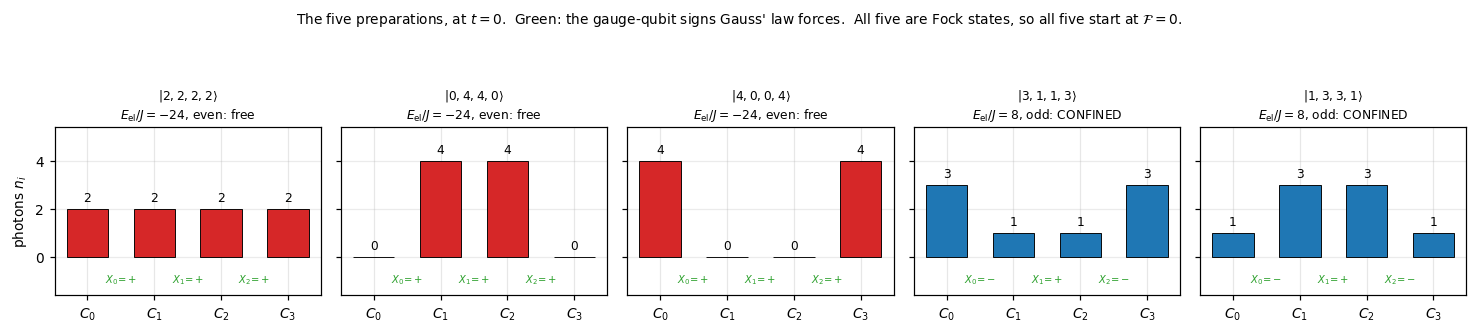

Every even preparation has the same energy at U=0, and never mixes with the odd ones.
F at t=0 is ZERO for all of them: a Fock state has no photon-number fluctuations.
What differs is the starting CONFIGURATION (last column) and the SECTOR (E_el).


In [4]:
GJ = 8.0                      # g/J
Uc = 3.0 / GJ                 # paper's boundary, U_c = 3 J^2 / g
PROBE, CONTROL = (2, 2, 2, 2), (3, 1, 1, 3)
CLUMP_IN, CLUMP_OUT = (0, 4, 4, 0), (4, 0, 0, 4)     # same sector as PROBE, clumped
PREPS = [PROBE, CLUMP_IN, CLUMP_OUT, CONTROL, (1, 3, 3, 1)]
US = np.array([0.0, 0.05, 0.1, 0.19, 0.28, 0.375, 0.5, 0.7, 0.9, 1.125, 1.5, 2.0])
JT_STAR = 2.0                 # the evolution time section 2 shows is needed

lat8 = Lattice(L, N_cut=8)                       # ideal-gate space
occ8 = np.array(lat8.bs, dtype=float)
print(f"g/J = {GJ},  U_c = 3J^2/g = {Uc},  N = 8 photons,  D = {lat8.D}")


def marginals(lt, vec):
    """P(n_i) for each cavity: trace out the gauge qubits."""
    p = np.abs(np.asarray(vec).ravel()) ** 2
    pb = p.reshape(lt.dq, lt.nb).sum(axis=0)
    return pb / pb.sum()


def F_from_pb(pb, occ):
    """The order parameter from a boson-basis probability vector."""
    n = pb @ occ
    return float((pb @ occ ** 2 - n ** 2).mean())


F_state = lambda lt, occ, v: F_from_pb(marginals(lt, v), occ)
contrast = lambda F0, F1: F0 / F1

U_TICKS = [0.0, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]
U_LABELS = ["0", "0.05", "0.1", "0.2", "0.5", "1", "2"]


def u_axis(ax, mark_uc=True):
    """Shared U/J axis: symlog through zero, readable ticks, the U_c marker."""
    ax.set_xscale("symlog", linthresh=0.05)
    ax.set_xlim(0, 2.2)
    ax.xaxis.set_major_locator(mticker.FixedLocator(U_TICKS))
    ax.xaxis.set_major_formatter(mticker.FixedFormatter(U_LABELS))
    ax.xaxis.set_minor_locator(mticker.FixedLocator([]))
    ax.set_xlabel("$U/J$")
    if mark_uc:
        ax.axvline(Uc, color="grey", ls=":", lw=1)
        ax.annotate("$U_c=3J^2/g$", (Uc, 0.97), xycoords=("data", "axes fraction"),
                    fontsize=7, color="grey", ha="right", va="top", rotation=90)


def ket(s):
    return "$|" + ",".join(str(x) for x in s) + r"\rangle$"


def prep_panel(ax, s, color, title=None, show_x=True):
    """Draw a preparation: the four cavity occupations and the gauge qubits it forces."""
    Eel = -GJ * sum((-1.0) ** int(np.sum(s[:l + 1])) for l in range(L - 1))
    ax.bar(range(L), s, 0.62, color=color, edgecolor="k", lw=0.6, zorder=3)
    for i, o in enumerate(s):
        ax.text(i, o + 0.18, str(o), ha="center", va="bottom", fontsize=8)
    if show_x:
        for l in range(L - 1):
            sg = (-1) ** int(np.sum(s[:l + 1]))
            ax.text(l + 0.5, -0.95, r"$X_{%d}\!=\!%s$" % (l, "+" if sg > 0 else "-"),
                    ha="center", va="center", fontsize=6.5, color="tab:green")
    ax.set(xticks=range(L), xticklabels=[f"$C_{i}$" for i in range(L)],
           ylim=(-1.6, 5.4), yticks=[0, 2, 4])
    ax.set_title(title or (ket(s) + f"\n$E_{{\\rm el}}/J={Eel:.0f}$, " +
                           ("even: free" if Eel < 0 else "odd: CONFINED")), fontsize=8)
    ax.grid(axis="y", alpha=0.25)


# --- every candidate preparation, its Gauss sector, and what it starts from
rows = []
for s in PREPS:
    Eel = -GJ * sum((-1.0) ** int(np.sum(s[:l + 1])) for l in range(L - 1))
    v = lat8.physical_state(s)
    rows.append({"preparation": str(s), "site parities": str(tuple(o % 2 for o in s)),
                 "E_el/J": Eel, "<H>/J at U=0": float(np.vdot(v, lat8.H(GJ, 1, 0) @ v).real),
                 "F at t=0": F_state(lat8, occ8, v),
                 "spread of n_i at t=0": float(np.std(s)),
                 "sector": "even: free to bunch" if Eel < 0 else "odd: CONFINED"})
display(pd.DataFrame(rows).set_index("preparation"))

fig, ax = plt.subplots(1, 5, figsize=(13.5, 2.7), sharey=True)
for k, s in enumerate(PREPS):
    prep_panel(ax[k], s, "tab:red" if k < 3 else "tab:blue")
ax[0].set_ylabel("photons $n_i$")
fig.suptitle("The five preparations, at $t=0$.  Green: the gauge-qubit signs Gauss' law "
             "forces.  All five are Fock states, so all five start at $\\mathcal{F}=0$.",
             fontsize=9, y=1.10)
plt.tight_layout(); plt.show()

print("Every even preparation has the same energy at U=0, and never mixes with the odd ones.")
print("F at t=0 is ZERO for all of them: a Fock state has no photon-number fluctuations.")
print("What differs is the starting CONFIGURATION (last column) and the SECTOR (E_el).")


### 1.2b Where $U_c$ comes from &mdash; and which of the paper's two numbers to use

[arXiv:2503.03828](https://arxiv.org/abs/2503.03828) derives an effective Hamiltonian by
Schrieffer-Wolff in the regime $U\ll J\ll g$ (their Eq. 4):

$$\hat H_{\rm eff}\approx-g\sum_i\hat Z_i-J_{\rm pair}\sum_i\hat Z_i\left(\hat a_i^{\dagger2}\hat a_{i+1}^2+{\rm h.c.}\right)-2J_{\rm pair}\sum_i\hat Z_i\hat n_i(\hat n_{i+1}+1)+\dots,\qquad J_{\rm pair}=\frac{J^2}{2g}.$$

The bunching is driven by the **third** term, a gauge-induced nearest-neighbour attraction;
the second is the resonant channel that lets bosons rearrange without paying electric energy.
Balancing the attraction against $U$ gives the boundary of the bunching region.

**The paper quotes two numbers for that boundary and they differ by a factor of two.** The
text solves $\langle\psi_{\rm bunch}|\hat H|\psi_{\rm bunch}\rangle=0$ and finds
$U_c=6J_{\rm pair}=3J^2/g$; the line drawn on their Fig. 2d is $U_c/J=6\,(g/J)^{-1}$, i.e.
$U_c=6J^2/g$. The discrepancy traces to their Eq. (1) writing the on-site term as
$\frac U2\sum\hat n_i^2$ while their Eq. (4) writes it as $U\sum\hat n_i^2$.

Rather than pick one, the cell below **measures both ingredients on this system**: the pair
hopping amplitude from an exactly solvable two-site problem, and the boundary itself from the
ground state of the gauge-fixed model at the filling this notebook actually uses.

**This settles which value to use here; it does not adjudicate the paper's factor of two.**
A cross-check at *their* filling with *our* open boundaries gives a coefficient near 2, not 3
($L{=}6$, $N{=}6$: 2.12→2.24 over $g/J=8\ldots32$ by the half-fall metric; $L{=}8$, $N{=}8$:
1.78→2.05), and at unit filling the steepest-descent and half-fall metrics disagree badly
(0.83 vs 2.12 at $L{=}6$), so "the boundary" is metric-dependent there. Their Fig. 2d is
$L{=}6$ with **periodic** boundaries, which is not reproduced anywhere in this notebook.
What is solid: nothing in any of these settings comes near 6, and at the filling and geometry
used here the coefficient is 3.

> **Two deviations from the paper, stated up front.** It studies the *ground state* at *unit
> filling* with *periodic* boundaries. This notebook runs a *quench* at *filling 2* ($N=8$ on
> $L=4$; \u00a71.4 shows unit filling on four sites has no usable preparation) with *open*
> boundaries. The mechanism is the same and \u00a71.3 checks the ground state too, but the
> phase-diagram coordinates are not literally theirs. Also, their order parameter is
> $(\langle\hat n_i^2\rangle-\langle\hat n_i\rangle^2)/L$ while $\mathcal F$ here is the site
> average of $\mathrm{Var}(n_i)$ &mdash; the same quantity up to a constant at fixed $L$, and
> every number reported is a ratio.


In [5]:
# ---------------- (a) the pair-hopping amplitude, measured
# Two sites, two bosons.  |2,0> and |0,2> both have even site parities -> E_el = -g;
# |1,1> is odd -> +g.  So the pair hop is a second-order process through a state 2g up,
# and the |2,0>/|0,2> splitting IS twice its amplitude.  Eq. (4) writes the pair term as
# -J_pair (a_i^+2 a_j^2 + h.c.), whose matrix element here is 2, so splitting = 4 J_pair.
rows = []
for g in (4.0, 8.0, 16.0, 32.0, 64.0):
    E = np.sort(np.linalg.eigvalsh(np.asarray(EffectiveBoson(2, 2).H(g, 1.0, 0.0).todense())))
    Jp = (E[1] - E[0]) / 4
    rows.append({"g/J": g, "splitting/J": E[1] - E[0], "J_pair measured": Jp,
                 "J^2/2g": 1 / (2 * g), "ratio": Jp / (1 / (2 * g))})
display(pd.DataFrame(rows).set_index("g/J"))
print("=> J_pair = J^2/(2g), to 0.1% by g/J = 32.  (Not 2J^2/g.)")

# ---------------- (b) the bunching boundary on THIS system, measured
# Ground state of the gauge-fixed boson model, L=4 at N=8.  U* = steepest descent of F(U).
U_SCAN = np.concatenate([[0.0], np.geomspace(0.005, 3.0, 80)])
ef_c = EffectiveBoson(L, 8)
occ_c = np.array(ef_c.bs, dtype=float)
rows = []
for g in (8.0, 12.0, 16.0, 24.0, 32.0, 48.0):
    F = []
    for u in U_SCAN:
        v = np.linalg.eigh(np.asarray(ef_c.H(g, 1.0, u).todense()))[1][:, 0]
        p = np.abs(v) ** 2
        n = p @ occ_c
        F.append(float((p @ occ_c ** 2 - n ** 2).mean()))
    F = np.array(F)
    Ustar = U_SCAN[int(np.argmax(-np.gradient(F, U_SCAN)))]
    rows.append({"g/J": g, "U*/J measured": Ustar, "c = U* (g/J) / J": Ustar * g,
                 "3J^2/g": 3 / g, "6J^2/g": 6 / g})
df_uc = pd.DataFrame(rows).set_index("g/J")
display(df_uc)
print(f"c drifts from {df_uc['c = U* (g/J) / J'].iloc[0]:.2f} at g/J=8 to "
      f"{df_uc['c = U* (g/J) / J'].iloc[-1]:.2f} at g/J=48, i.e. it converges on 3, not 6.")
print("==> this notebook uses U_c = 3 J^2/g = 6 J_pair, the paper's TEXT value, because")
print("    that is what our own ground state gives.  At the g/J = 8 operating point the")
print("    true boundary sits ~17% below it -- the perturbative estimate is asymptotic,")
print("    so treat U_c as a scale, not a sharp prediction.")

# ---------------- (c) the two Gauss sectors are two different playgrounds
import itertools
for tag, par in (("even", 0), ("odd", 1)):
    cfg = [t for t in itertools.product(range(9), repeat=L)
           if sum(t) == 8 and all(x % 2 == par for x in t)]
    q = [sum(x * x for x in t) for t in cfg]
    print(f"{tag:>5} sector: {len(cfg):2d} configurations, n_i in "
          f"{sorted(set(x for t in cfg for x in t))}, sum n_i^2 from {min(q)} to {max(q)}"
          f"  (range {max(q)-min(q)})")
print("Pair hopping conserves every site parity, so a preparation never leaves its own")
print("list.  The odd list has no configuration with an empty site: it cannot bunch.")


,splitting/J,J_pair measured,J^2/2g,ratio
g/J,,,,
4.0,0.47214,0.11803,0.12500,0.94427
8.0,0.24621,0.06155,0.06250,0.98485
16.0,0.12452,0.03113,0.03125,0.99612
32.0,0.06244,0.01561,0.01562,0.99903
64.0,0.03124,0.00781,0.00781,0.99976


=> J_pair = J^2/(2g), to 0.1% by g/J = 32.  (Not 2J^2/g.)


,U*/J measured,c = U* (g/J) / J,3J^2/g,6J^2/g
g/J,,,,
8.0,0.31079,2.48628,0.37500,0.7500
12.0,0.22480,2.69759,0.25000,0.5000
16.0,0.17632,2.82108,0.18750,0.3750
24.0,0.11761,2.82276,0.12500,0.2500
32.0,0.09225,2.95198,0.09375,0.1875
48.0,0.06154,2.95374,0.06250,0.1250


c drifts from 2.49 at g/J=8 to 2.95 at g/J=48, i.e. it converges on 3, not 6.
==> this notebook uses U_c = 3 J^2/g = 6 J_pair, the paper's TEXT value, because
    that is what our own ground state gives.  At the g/J = 8 operating point the
    true boundary sits ~17% below it -- the perturbative estimate is asymptotic,
    so treat U_c as a scale, not a sharp prediction.
 even sector: 35 configurations, n_i in [0, 2, 4, 6, 8], sum n_i^2 from 16 to 64  (range 48)
  odd sector: 10 configurations, n_i in [1, 3, 5], sum n_i^2 from 20 to 28  (range 8)
Pair hopping conserves every site parity, so a preparation never leaves its own
list.  The odd list has no configuration with an empty site: it cannot bunch.


### 1.3 The equilibrium crossover, and the quench that reproduces it

Two independent looks at the same physics:

* **Ground state** of the 165-dimensional gauge-fixed boson model — the textbook order
  parameter, exact diagonalization, no circuit involved.
* **Quench**: prepare a Fock state, evolve under $\tilde H$, read $\mathcal F$ at $Jt=2$.
  This is what an experiment actually does.

Both place the crossover at the same scale. As §1.2b measured, the steepest-descent
point of the ground-state curve lands about 17% below $U_c=3J^2/g$ at $g/J=8$ and converges
onto it as $g/J$ grows &mdash; the perturbative estimate is asymptotic in $J/g$, so treat
$U_c$ as a scale rather than a sharp prediction at $g/J=8$.

In [6]:
# ---------------- equilibrium: ground-state order parameter
ef8 = EffectiveBoson(L, 8)
occ_e = np.array(ef8.bs, dtype=float)
U_fine = np.concatenate([[0.0], np.geomspace(0.02, 3.0, 40)])
F_gs = np.array([F_from_pb(np.abs(np.linalg.eigh(
    np.asarray(ef8.H(GJ, 1.0, u).todense()))[1][:, 0]) ** 2, occ_e) for u in U_fine])
U_star = U_fine[int(np.argmax(-np.gradient(F_gs, U_fine)))]
R_gs = F_gs[0] / np.interp(3 * Uc, U_fine, F_gs)
print(f"ground state : F(0) = {F_gs[0]:.3f} -> F(3Uc) = "
      f"{np.interp(3*Uc, U_fine, F_gs):.3f},  R = {R_gs:.1f}x")
print(f"               steepest descent at U/J = {U_star:.3f}  (theory U_c = {Uc:.3f})")


# ---------------- quench
def quench(lt, occ, start, U, ts, g=GJ):
    """Exact time evolution with qutip sesolve.  Returns <n_i>(t), F(t)."""
    H = qt.Qobj(lt.H(g, 1.0, U).tocsr(), dims=[[lt.D], [lt.D]])
    psi0 = qt.Qobj(lt.physical_state(start).reshape(-1, 1), dims=[[lt.D], [1]])
    res = qt.sesolve(H, psi0, ts, options={"atol": 1e-10, "rtol": 1e-8})
    n_t, F_t = [], []
    for st in res.states:
        pb = marginals(lt, st.full())
        n_t.append(pb @ occ)
        F_t.append(F_from_pb(pb, occ))
    return np.array(n_t).T, np.array(F_t)


t0 = time.time()
TS = np.linspace(0, JT_STAR, 33)
F_quench = {s: np.array([quench(lat8, occ8, s, u, TS)[1][-1] for u in US])
            for s in (PROBE, CONTROL)}
R_probe = contrast(F_quench[PROBE][0], F_quench[PROBE][US == 1.125][0])
R_ctrl = contrast(F_quench[CONTROL][0], F_quench[CONTROL][US == 1.125][0])
print(f"quench Jt={JT_STAR}: probe   F {F_quench[PROBE][0]:.3f} -> "
      f"{F_quench[PROBE][US==1.125][0]:.3f}   R = {R_probe:.1f}x")
print(f"                    control F {F_quench[CONTROL][0]:.3f} -> "
      f"{F_quench[CONTROL][US==1.125][0]:.3f}   R = {R_ctrl:.1f}x")
print(f"[{time.time()-t0:.0f}s]")

ground state : F(0) = 1.915 -> F(3Uc) = 0.097,  R = 19.8x
               steepest descent at U/J = 0.297  (theory U_c = 0.375)


quench Jt=2.0: probe   F 2.525 -> 0.199   R = 12.7x
                    control F 1.233 -> 1.009   R = 1.2x
[3s]


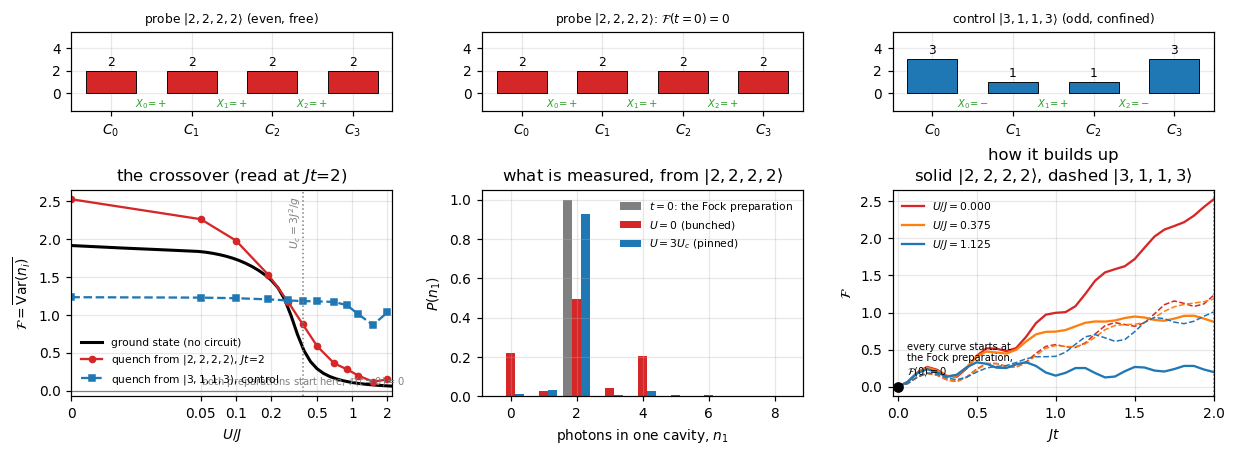

P(n=2): 0.495 at U=0  vs  0.927 at U=3Uc
P(n=0): 0.221          vs  0.012
P(n=4): 0.203          vs  0.026
Both columns START from the grey bar: P(n=2)=1, F=0.  At U=0 the distribution
spreads to 0/2/4 photons; at 3U_c it barely leaves the preparation.
That single histogram IS the measurement -- F is just its second moment.


In [7]:
# ---------------- the money figure: crossover + the histogram behind it
hist = {}
for U in (0.0, 3 * Uc):
    H = qt.Qobj(lat8.H(GJ, 1.0, U).tocsr(), dims=[[lat8.D], [lat8.D]])
    psi0 = qt.Qobj(lat8.physical_state(PROBE).reshape(-1, 1), dims=[[lat8.D], [1]])
    st = qt.sesolve(H, psi0, [0, JT_STAR], options={"atol": 1e-10}).states[-1]
    pb = marginals(lat8, st.full())
    hist[U] = np.array([pb[occ8[:, 0] == n].sum() for n in range(9)])
hist0 = np.array([1.0 if n == PROBE[0] else 0.0 for n in range(9)])       # t = 0

fig = plt.figure(figsize=(13.4, 4.3))
gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 2.6], hspace=0.55, wspace=0.28)
axp = [fig.add_subplot(gs[0, k]) for k in range(3)]
ax = [fig.add_subplot(gs[1, k]) for k in range(3)]

prep_panel(axp[0], PROBE, "tab:red", title="probe " + ket(PROBE) + " (even, free)")
prep_panel(axp[1], PROBE, "tab:red", title="probe " + ket(PROBE) + r": $\mathcal{F}(t{=}0)=0$")
prep_panel(axp[2], CONTROL, "tab:blue", title="control " + ket(CONTROL) + " (odd, confined)")

ax[0].plot(U_fine, F_gs, "k-", lw=2, label="ground state (no circuit)")
ax[0].plot(US, F_quench[PROBE], "o-", color="tab:red", ms=4,
           label=f"quench from {ket(PROBE)}, $Jt$={JT_STAR:.0f}")
ax[0].plot(US, F_quench[CONTROL], "s--", color="tab:blue", ms=4,
           label=f"quench from {ket(CONTROL)}, control")
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].annotate(r"both preparations start here, $\mathcal{F}(t{=}0)=0$", (0.05, 0.02),
               xycoords=("data", "data"), fontsize=6.5, color="grey", va="bottom")
ax[0].set(ylabel=r"$\mathcal{F}=\overline{{\rm Var}(n_i)}$",
          title=f"the crossover (read at $Jt$={JT_STAR:.0f})")
u_axis(ax[0])
ax[0].legend(fontsize=7, loc="lower left")

w = 0.28
ax[1].bar(np.arange(9) - w, hist0, w, color="grey", label=r"$t=0$: the Fock preparation")
ax[1].bar(np.arange(9), hist[0.0], w, color="tab:red", label="$U=0$ (bunched)")
ax[1].bar(np.arange(9) + w, hist[3 * Uc], w, color="tab:blue", label="$U=3U_c$ (pinned)")
ax[1].set(xlabel="photons in one cavity, $n_1$", ylabel="$P(n_1)$",
          title=f"what is measured, from {ket(PROBE)}")
ax[1].legend(fontsize=7)

for U, c in ((0.0, "tab:red"), (Uc, "tab:orange"), (3 * Uc, "tab:blue")):
    _, F = quench(lat8, occ8, PROBE, U, TS)
    ax[2].plot(TS, F, color=c, label=f"$U/J={U:.3f}$")
    _, Fc = quench(lat8, occ8, CONTROL, U, TS)
    ax[2].plot(TS, Fc, color=c, ls="--", lw=1)
ax[2].plot(0, 0, "ko", ms=6, zorder=5)
ax[2].annotate("every curve starts at\nthe Fock preparation,\n"
               r"$\mathcal{F}(0)=0$", (0.06, 0.12), fontsize=6.5, va="bottom")
ax[2].axvline(JT_STAR, color="grey", ls=":", lw=1)
ax[2].set(xlabel="$Jt$", ylabel=r"$\mathcal{F}$", xlim=(-0.03, TS[-1]),
          title="how it builds up\nsolid " + ket(PROBE) + ", dashed " + ket(CONTROL))
ax[2].legend(fontsize=7)
plt.show()

print(f"P(n=2): {hist[0.0][2]:.3f} at U=0  vs  {hist[3*Uc][2]:.3f} at U=3Uc")
print(f"P(n=0): {hist[0.0][0]:.3f}          vs  {hist[3*Uc][0]:.3f}")
print(f"P(n=4): {hist[0.0][4]:.3f}          vs  {hist[3*Uc][4]:.3f}")
print("Both columns START from the grey bar: P(n=2)=1, F=0.  At U=0 the distribution")
print("spreads to 0/2/4 photons; at 3U_c it barely leaves the preparation.")
print("That single histogram IS the measurement -- F is just its second moment.")


### 1.4 Why eight photons, and why $\langle n_i\rangle$ will not do

Two control checks that decide the experiment.

In [8]:
rows = []
for N, starts in ((4, [(1, 1, 1, 1), (2, 2, 0, 0)]), (8, [PROBE, (0, 4, 4, 0), CONTROL])):
    lt = Lattice(L, N_cut=N)
    oc = np.array(lt.bs, dtype=float)
    for s in starts:
        F0 = quench(lt, oc, s, 0.0, TS)[1][-1]
        F1 = quench(lt, oc, s, 3 * Uc, TS)[1][-1]
        n_t, _ = quench(lt, oc, s, 0.0, TS)
        n_hi, _ = quench(lt, oc, s, 3 * Uc, TS)
        Eel = -GJ * sum((-1.0) ** int(np.sum(s[:l + 1])) for l in range(L - 1))
        rows.append({"N": N, "start": str(s), "sector": "even" if Eel < 0 else "odd",
                     "F(U=0)": F0, "F(3Uc)": F1, "contrast R": F0 / F1,
                     "spread of <n_i>, U=0": n_t[:, -1].std(),
                     "spread of <n_i>, 3Uc": n_hi[:, -1].std()})
df_choice = pd.DataFrame(rows).set_index(["N", "start"])
display(df_choice)
print("N=4: the uniform state (1,1,1,1) has all-ODD parities, so at unit filling the")
print("     natural spread preparation is CONFINED -- contrast 1.5x, no signal.  An")
print("     even N=4 preparation such as (2,2,0,0) does show a crossover (5.4x), but")
print("     it is already clumped at t=0 and less than half the N=8 contrast.")
print("N=8: (2,2,2,2) is even, uniform AND free.  Contrast 12.7x.  ==> eight photons.")
print()
print()
print("Last two columns: for (2,2,2,2) the site-to-site spread of <n_i> is BELOW 0.03")
print("photons at both U=0 and U=3Uc.  The mean occupation cannot separate the phases;")
print("only the variance can.  That is why F, not <n_i>, is the observable.")

sector   F(U=0)   F(3Uc)  contrast R  spread of <n_i>, U=0  spread of <n_i>, 3Uc
N start                                                                                        
4 (1, 1, 1, 1)    odd  0.09426  0.06092     1.54737               0.01369               0.01644
  (2, 2, 0, 0)   even  1.03554  0.19281     5.37080               0.92876               0.93742
8 (2, 2, 2, 2)   even  2.52502  0.19867    12.70952               0.02112               0.00309
  (0, 4, 4, 0)   even  3.23879  0.55147     5.87301               1.30779               1.89912
  (3, 1, 1, 3)    odd  1.23312  1.00879     1.22238               0.22021               0.38154

N=4: the uniform state (1,1,1,1) has all-ODD parities, so at unit filling the
     natural spread preparation is CONFINED -- contrast 1.5x, no signal.  An
     even N=4 preparation such as (2,2,0,0) does show a crossover (5.4x), but
     it is already clumped at t=0 and less than half the N=8 contrast.
N=8: (2,2,2,2) is even, uniform AND free.  Contrast 12.7x.  ==> eight photons.


Last two columns: for (2,2,2,2) the site-to-site spread of <n_i> is BELOW 0.03
photons at both U=0 and U=3Uc.  The mean occupation cannot separate the phases;
only the variance can.  That is why F, not <n_i>, is the observable.


### 1.5 Three preparations, three different questions

The experiment runs more than one preparation. They are not repeats: each pair isolates a
different piece of physics, and it matters which one is being quoted.

All of them are Fock states, so **all of them start at $\mathcal F=0$**; $\mathcal F$ is
built by the dynamics. What differs is the initial condition it is built from.

| | $\lvert 2,2,2,2\rangle$ | $\lvert 3,1,1,3\rangle$ | $\lvert 0,4,4,0\rangle$, $\lvert 4,0,0,4\rangle$ |
|---|---|---|---|
| site parities | even | odd | even |
| $E_{\rm el}$ | $-3g$ | $+g$ | $-3g$ |
| sector | free | **confined** | free |
| starting profile | flat | flat | **clumped** |
| role | probe | control | memory probe |

**$(2,2,2,2)$ vs $(3,1,1,3)$ changes the *sector*, not the profile.** Both are flat to
within one photon; they differ by moving a single photon between neighbours, which flips
every site parity. Gauss' law then forces a different electric-field configuration, and the
two differ in energy by $4g=32J$ &mdash; they cannot mix, ever. The odd preparation is *not*
frozen: pair hops are resonant for it too, and it rearranges freely (numerically, 83% of it
leaves its initial configuration within one pair-hop time). What it cannot do is **bunch**,
because odd parity pins $n_i\in\{1,3,5\}$ on every site &mdash; it can never empty one. Its
ten reachable configurations span $\sum_i n_i^2 = 20\ldots28$ against $16\ldots64$ for the
even sector, so $U$ has almost nothing to act on and its $\mathcal F$ barely moves **for any
$U$**. That is what makes it the control: flat is not an empirical observation about it, it
follows from a conservation law.

**$(2,2,2,2)$ vs $(0,4,4,0)$ changes the *profile*, not the sector.** Identical parities,
identical $E_{\rm el}=-3g$, identical $\langle H\rangle$ at $U=0$, identical conserved
quantities. The only difference is where the eight photons sit at $t=0$. So this pair asks a
question the probe/control pair cannot: does the system *forget* how it was prepared?

* at $U=0$ the two run **towards** each other &mdash; the flat state bunches up and the clump
  melts;
* at $U=3U_c$ they run **apart and stop** &mdash; the flat state stays pinned and the clump
  self-traps.

So probe-vs-control tests **confinement** and flat-vs-clumped tests **memory**. They are
independent, and the second one costs nothing but a different preparation. Section 6 turns
it into a measurement that does not need a tunable $U$ at all.

**Why $(2,2,2,2)$ is the headline probe.** It starts at the extreme of the order parameter
&mdash; zero variance *and* a flat profile &mdash; so $U=0$ has the most room to build variance
while $U\gg U_c$ has nothing to do. The clumped starts already have somewhere to go at both
ends of the $U$ axis, so their ratio is smaller: 5.9$\times$ and 5.4$\times$ against
12.7$\times$. That is the whole reason they are not the headline number, and it is worth
being explicit that they *do* show the same crossover.

**Why $(4,0,0,4)$ behaves differently from $(0,4,4,0)$.** Both are even and clumped, but
$(4,0,0,4)$ puts its two clumps at opposite ends of a four-site chain, so they have to
traverse it before anything can mix. It is the slowest preparation of the three and the
weakest at fixed wall time. Run it as a check that the answer does not depend on *where*
the photons were put, not as the main probe.


,sector,F(U=0) Jt=2,F(U=0) Jt=6,F(3Uc) Jt=2,F(3Uc) Jt=6,contrast R,imbalance(U=0) Jt=6,imbalance(3Uc) Jt=6
preparation,,,,,,,,
"(2, 2, 2, 2)",even,2.52502,3.19023,0.19867,0.21607,12.70952,NaN,NaN
"(0, 4, 4, 0)",even,3.23879,5.02800,0.55147,0.51955,5.87301,0.25460,0.93938
"(4, 0, 0, 4)",even,0.99501,4.18019,0.18538,0.54132,5.36757,0.25745,0.91342
"(3, 1, 1, 3)",odd,1.23312,1.43596,1.00879,1.17991,1.22238,NaN,NaN
"(1, 3, 3, 1)",odd,1.94513,1.59086,1.11699,0.90583,1.74141,NaN,NaN


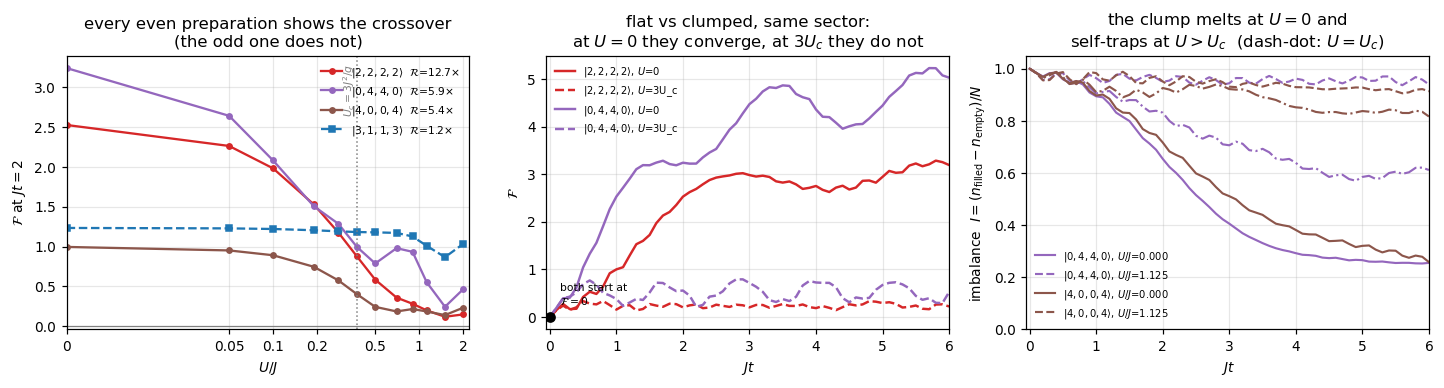

[14s]
Left  : (2,2,2,2) 12.7x, (0,4,4,0) 5.9x, (4,0,0,4) 5.4x -- the crossover does NOT
        depend on which even state you load; only its size does.  (3,1,1,3): 1.2x.
Middle: same sector, same energy, different profile.  At U=0 the flat and clumped
        preparations converge (the system forgets); at 3U_c they stay apart.
Right : the SAME physics in <n_i> alone -- no variance, no histogram needed.  This
        is the observable section 6 uses when U cannot be tuned.


In [9]:
# ------------- what each preparation comparison isolates
t0 = time.time()
TS_MED = np.linspace(0, 6, 61)
SGN = {CLUMP_IN: np.array([-1.0, 1, 1, -1]), CLUMP_OUT: np.array([1.0, -1, -1, 1])}


def imbalance(nt, s):
    """(photons on initially-filled sites - photons on initially-empty sites)/N."""
    return (SGN[s] @ nt) / sum(s)


rows = []
for s in PREPS:
    r = {"preparation": str(s), "sector": "even" if sum(o % 2 for o in s) == 0 else "odd"}
    for U, tag in ((0.0, "U=0"), (3 * Uc, "3Uc")):
        n_t, F_t = quench(lat8, occ8, s, U, TS_MED)
        r[f"F({tag}) Jt=2"] = F_t[20]
        r[f"F({tag}) Jt=6"] = F_t[-1]
        if s in SGN:
            r[f"imbalance({tag}) Jt=6"] = imbalance(n_t[:, -1], s)
    r["contrast R"] = r["F(U=0) Jt=2"] / r["F(3Uc) Jt=2"]
    rows.append(r)
df_prep = pd.DataFrame(rows).set_index("preparation")
display(df_prep)

fig, ax = plt.subplots(1, 3, figsize=(13.2, 3.6))

for s, c in ((PROBE, "tab:red"), (CLUMP_IN, "tab:purple"), (CLUMP_OUT, "tab:brown"),
             (CONTROL, "tab:blue")):
    F0 = np.array([quench(lat8, occ8, s, u, TS)[1][-1] for u in US])
    i3 = int(np.argmin(abs(US - 3 * Uc)))
    ax[0].plot(US, F0, "o-" if s != CONTROL else "s--", ms=3.5, color=c,
               label=f"{ket(s)}  $\\mathcal{{R}}$={F0[0]/F0[i3]:.1f}$\\times$")
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set(ylabel=r"$\mathcal{F}$ at $Jt=2$",
          title="every even preparation shows the crossover\n(the odd one does not)")
u_axis(ax[0])
ax[0].legend(fontsize=7, loc="upper right")

for s, c in ((PROBE, "tab:red"), (CLUMP_IN, "tab:purple")):
    for U, ls in ((0.0, "-"), (3 * Uc, "--")):
        _, F_t = quench(lat8, occ8, s, U, TS_MED)
        ax[1].plot(TS_MED, F_t, ls, color=c, lw=1.6,
                   label=f"{ket(s)}, $U$={'0' if U == 0 else '3U_c'}")
ax[1].plot(0, 0, "ko", ms=6, zorder=5)
ax[1].annotate("both start at\n" + r"$\mathcal{F}=0$", (0.15, 0.25), fontsize=7)
ax[1].set(xlabel="$Jt$", ylabel=r"$\mathcal{F}$", xlim=(-0.05, 6),
          title="flat vs clumped, same sector:\nat $U=0$ they converge, at $3U_c$ they do not")
ax[1].legend(fontsize=6.5, loc="upper left")

for s, c in ((CLUMP_IN, "tab:purple"), (CLUMP_OUT, "tab:brown")):
    for U, ls in ((0.0, "-"), (Uc, "-."), (3 * Uc, "--")):
        n_t, _ = quench(lat8, occ8, s, U, TS_MED)
        ax[2].plot(TS_MED, [imbalance(n_t[:, k], s) for k in range(len(TS_MED))], ls,
                   color=c, lw=1.4,
                   label=f"{ket(s)}, $U/J$={U:.3f}" if U != Uc else None)
ax[2].set(xlabel="$Jt$", ylabel="imbalance  $I=(n_{\\rm filled}-n_{\\rm empty})/N$",
          ylim=(0, 1.05), xlim=(-0.05, 6),
          title="the clump melts at $U=0$ and\nself-traps at $U>U_c$  (dash-dot: $U=U_c$)")
ax[2].legend(fontsize=6.5, loc="lower left")
plt.tight_layout(); plt.show()

print(f"[{time.time()-t0:.0f}s]")
print("Left  : (2,2,2,2) 12.7x, (0,4,4,0) 5.9x, (4,0,0,4) 5.4x -- the crossover does NOT")
print("        depend on which even state you load; only its size does.  (3,1,1,3): 1.2x.")
print("Middle: same sector, same energy, different profile.  At U=0 the flat and clumped")
print("        preparations converge (the system forgets); at 3U_c they stay apart.")
print("Right : the SAME physics in <n_i> alone -- no variance, no histogram needed.  This")
print("        is the observable section 6 uses when U cannot be tuned.")


### Section 1 verdict

* The equilibrium and quench crossovers agree and sit on $U_c=3J^2/g=6J_{\rm pair}$,
  which §1.2b measures rather than assumes.
* At $N=8$, $\mathcal F$ collapses **12.7$\times$** across the crossover for the even probe
  and only **1.3$\times$** for the odd control.
* The signature is directly visible in a single-cavity photon histogram: $P(n{=}2)=0.50$ at
  $U=0$ versus $0.93$ at $U=3U_c$.
* $N=4$ does not work, and $\langle n_i\rangle$ is the wrong observable.

---
## 2. Synthesis: which Trotterization, how long, how many gates

The controlled beamsplitter is not driven directly. It is the **group commutator** of the
two $g1e0$ sideband legs of a link: with pump phases $\phi-\psi=\pi/2$,

$$i\left[\bar A^{(l,l)}_{\pi/2},\bar B^{(l,l+1)}_{0}\right]=\hat Z_l\left(a_l^\dagger a_{l+1}+{\rm h.c.}\right),$$

so four pulses of area $\epsilon$ buy an angle $\theta=\epsilon^2$. The variants differ in
which BCH error orders they cancel:

| sequence | $\theta$ | sideband pulses | $\pi$ pulses | cancels |
|---|---|---|---|---|
| $W$ | $\epsilon^2$ | 4 | 0 | — |
| $W_{\rm sym}=W(\epsilon)W(-\epsilon)$ | $2\epsilon^2$ | 8 | 0 | the odd $O(\epsilon^3)$ term |
| $W_{\rm gauge}$ | $2\epsilon^2$ | 8 | 2 | the gauge-odd part only |
| $W_{\rm full}$ | $4\epsilon^2$ | 16 | 2 | both |

Sign reversal is free ($A_{\phi+\pi}=-A_\phi$), so $W_{\rm sym}$ costs nothing but the
doubling it already pays for. The layer order is forced by connectivity: links 0 and 2 touch
disjoint cavities *and* disjoint transmons, so they fire together; link 1 is a second layer.

Two questions, in order: **how much $Jt$ do we need**, then **what does that cost**.

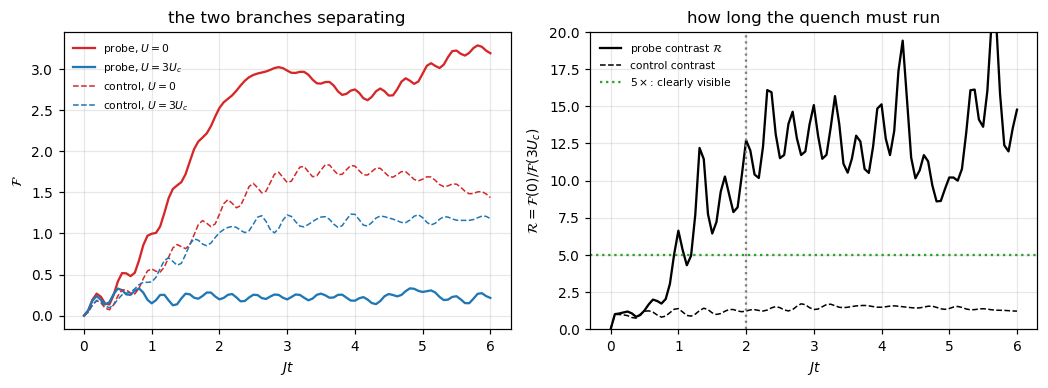

  Jt =  0.5:  probe R =  1.26x,  control R = 1.21x
  Jt =  1.0:  probe R =  6.62x,  control R = 1.39x
  Jt =  1.5:  probe R =  6.44x,  control R = 1.10x
  Jt =  2.0:  probe R = 12.71x,  control R = 1.22x
  Jt =  3.0:  probe R = 15.07x,  control R = 1.32x
  Jt =  4.0:  probe R = 15.13x,  control R = 1.48x

==> Jt = 2 is the target: the contrast is already >10x there and only
    creeps up afterwards, while every extra Jt costs wall-clock and photons.


In [10]:
# ---------------- how long must the quench run?
TS_LONG = np.linspace(0, 6, 97)
_, Fp0 = quench(lat8, occ8, PROBE, 0.0, TS_LONG)
_, Fp1 = quench(lat8, occ8, PROBE, 3 * Uc, TS_LONG)
_, Fc0 = quench(lat8, occ8, CONTROL, 0.0, TS_LONG)
_, Fc1 = quench(lat8, occ8, CONTROL, 3 * Uc, TS_LONG)
with np.errstate(divide="ignore", invalid="ignore"):
    R_t, Rc_t = Fp0 / np.maximum(Fp1, 1e-12), Fc0 / np.maximum(Fc1, 1e-12)

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.6))
ax[0].plot(TS_LONG, Fp0, color="tab:red", label="probe, $U=0$")
ax[0].plot(TS_LONG, Fp1, color="tab:blue", label="probe, $U=3U_c$")
ax[0].plot(TS_LONG, Fc0, color="tab:red", ls="--", lw=1, label="control, $U=0$")
ax[0].plot(TS_LONG, Fc1, color="tab:blue", ls="--", lw=1, label="control, $U=3U_c$")
ax[0].set(xlabel="$Jt$", ylabel=r"$\mathcal{F}$", title="the two branches separating")
ax[0].legend(fontsize=7)
ax[1].plot(TS_LONG, R_t, "k-", label="probe contrast $\\mathcal{R}$")
ax[1].plot(TS_LONG, Rc_t, "k--", lw=1, label="control contrast")
ax[1].axhline(5, color="tab:green", ls=":", label="$5\\times$: clearly visible")
ax[1].axvline(JT_STAR, color="grey", ls=":")
ax[1].set(xlabel="$Jt$", ylabel=r"$\mathcal{R}=\mathcal{F}(0)/\mathcal{F}(3U_c)$",
          ylim=(0, 20), title="how long the quench must run")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

for jt in (0.5, 1.0, 1.5, 2.0, 3.0, 4.0):
    k = int(np.argmin(abs(TS_LONG - jt)))
    print(f"  Jt = {jt:4.1f}:  probe R = {R_t[k]:5.2f}x,  control R = {Rc_t[k]:4.2f}x")
print(f"\n==> Jt = {JT_STAR:.0f} is the target: the contrast is already >10x there and only")
print("    creeps up afterwards, while every extra Jt costs wall-clock and photons.")

In [11]:
# ---------------- scheme comparison at Jt = 2, and what each costs
t0 = time.time()
G_SIDE = np.pi / (2 * T_SWAP)        # 1.25 MHz sideband, rad/us
T_PI_US = T_PI                       # 20 ns transmon pi pulse

lat10 = Lattice(L, N_cut=10)         # headroom: a sideband pulse can add a photon
occ10 = np.array(lat10.bs, dtype=float)
v0_10 = lat10.physical_state(PROBE)

F_ex = {u: F_state(lat10, occ10, evolve_exact(lat10.H(GJ, 1.0, u), v0_10, [JT_STAR])[-1])
        for u in (0.0, 3 * Uc)}
R_EX = F_ex[0.0] / F_ex[3 * Uc]
F_ex8 = F_state(lat8, occ8, evolve_exact(lat8.H(GJ, 1.0, 0.0),
                                         lat8.physical_state(PROBE), [JT_STAR])[-1])
print(f"exact at Jt={JT_STAR}: F(0)={F_ex[0.0]:.4f}, F(3Uc)={F_ex[3*Uc]:.4f}, "
      f"R = {R_EX:.2f}x")
print(f"truncation check: F(U=0) is {F_ex8:.4f} at N_cut=8 vs {F_ex[0.0]:.4f} at N_cut=10 "
      f"(rel {abs(F_ex8-F_ex[0.0])/F_ex[0.0]:.1e}) -- converged\n")

rows = []
for label, kind, scheme in [("Trotter-1, ideal gates", "ideal", None),
                            ("Trotter-2, ideal gates", "ideal2", None),
                            ("sideband W", "sb", "W"),
                            ("sideband Wsym", "sb", "Wsym"),
                            ("sideband Wgauge", "sb", "Wgauge"),
                            ("sideband Wfull", "sb", "Wfull")]:
    for nst in (20, 41, 80, 160):
        dt, F = JT_STAR / nst, {}
        for U in (0.0, 3 * Uc):
            if kind.startswith("ideal"):
                lay = ideal_layers(lat10, GJ, 1.0, U, dt, order=1 if kind == "ideal" else 2)
                eps = np.nan
            else:
                lay, eps = sideband_layers(lat10, GJ, 1.0, U, dt, G_SIDE,
                                           scheme=scheme, order=1)
            F[U] = F_state(lat10, occ10, run_layers(lay, v0_10, nst)[-1])
        R = F[0.0] / F[3 * Uc]
        n_sb = nst * 2 * N_SIDEBAND_PULSES[scheme] if scheme else np.nan
        n_pi = nst * 2 * N_PI_PULSES[scheme] if scheme else np.nan
        wall = nst * sideband_duration(eps, G_SIDE, scheme, T_PI_US, 1) if scheme else np.nan
        rows.append({"scheme": label, "steps": nst, "eps": eps, "R": R,
                     "|R-R_ex|/R_ex": abs(R - R_EX) / R_EX, "sideband pulses": n_sb,
                     "pi pulses": n_pi, "wall (us)": wall,
                     "J/2pi (kHz)": JT_STAR / wall / (2 * np.pi) * 1e3 if scheme else np.nan})
df_syn = pd.DataFrame(rows).set_index(["scheme", "steps"])
display(df_syn.style.format({"eps": "{:.4f}", "R": "{:.2f}", "|R-R_ex|/R_ex": "{:.3f}",
                             "sideband pulses": "{:.0f}", "pi pulses": "{:.0f}",
                             "wall (us)": "{:.1f}", "J/2pi (kHz)": "{:.1f}"}, na_rep="-"))
print(f"[{time.time()-t0:.0f}s]")

exact at Jt=2.0: F(0)=2.5250, F(3Uc)=0.1987, R = 12.71x
truncation check: F(U=0) is 2.5250 at N_cut=8 vs 2.5250 at N_cut=10 (rel 0.0e+00) -- converged



[123s]


In [12]:
ok = df_syn[df_syn["|R-R_ex|/R_ex"] < 0.10].reset_index()
print(f"=== cheapest setting within 10% of the exact contrast ({R_EX:.2f}x) ===")
cheapest = ok.sort_values("steps").groupby("scheme", as_index=False).first()
for _, r in cheapest.sort_values("scheme").iterrows():
    w = "-" if np.isnan(r["wall (us)"]) else f"{r['wall (us)']:.1f} us"
    p = "-" if np.isnan(r["sideband pulses"]) else f"{r['sideband pulses']:.0f}"
    print(f"  {r['scheme']:<24} steps={r['steps']:>4}  R={r['R']:5.2f}x  "
          f"pulses={p:>5}  wall={w}")
missing = sorted(set(df_syn.reset_index()['scheme']) - set(ok['scheme']))
print(f"\nnever reach 10%: {missing}")
print("  W is the bare group commutator: its O(eps^3) error never cancels.")
print("  Wgauge protects only the gauge-odd part, so it stalls too.")
print()
print("==> Wsym is the winner: symmetrizing is free, and it is the shortest in WALL TIME,")
print("    which is the only currency decoherence charges in.  Wfull needs fewer steps but")
print("    16 pulses each plus pi pulses, so it ends up longer.")

=== cheapest setting within 10% of the exact contrast (12.71x) ===
  Trotter-1, ideal gates   steps=  41  R=12.07x  pulses=    -  wall=-
  Trotter-2, ideal gates   steps=  41  R=12.01x  pulses=    -  wall=-
  sideband Wfull           steps=  41  R=12.06x  pulses= 1312  wall=21.7 us
  sideband Wsym            steps=  80  R=12.18x  pulses= 1280  wall=18.2 us

never reach 10%: ['sideband W', 'sideband Wgauge']
  W is the bare group commutator: its O(eps^3) error never cancels.
  Wgauge protects only the gauge-odd part, so it stalls too.

==> Wsym is the winner: symmetrizing is free, and it is the shortest in WALL TIME,
    which is the only currency decoherence charges in.  Wfull needs fewer steps but
    16 pulses each plus pi pulses, so it ends up longer.


### 2.3 What actually gets played

Everything above is a claim about a *circuit*. Here is the circuit, as pulses on physical
pump channels.

Each transmon $l$ owns exactly two sideband pumps: an **$A$ leg** to cavity $l$ and a **$B$
leg** to cavity $l+1$. One $W_{\rm sym}$ synthesis on a link is the eight-pulse train

$$B_-\;A_-\;B_+\;A_+\;\;\;B_+\;A_+\;B_-\;A_-$$

— the group commutator $W(-\epsilon)$ followed by $W(+\epsilon)$. The subscript is only the
**pump phase**: $A_{\phi+\pi}=-A_\phi$, so a "negative" pulse is the same pulse with its
phase shifted by $\pi$. That is the whole reason symmetrizing is free.

One Trotter step is then three layers:

1. **LOC** — a transmon $X$ rotation on all three qubits (the electric term), with the
   diagonal $U$ term riding along for free.
2. **L13** — the eight-pulse train on links 0 and 2 **simultaneously**: they touch disjoint
   cavities *and* disjoint transmons, so their pulse Hamiltonians commute exactly.
3. **L2** — the same train on link 1, which overlaps both.

Wsym, 41 steps:  eps = 0.1562,  one sideband pulse = 19.9 ns,  one Trotter step = 338 ns
per step: 1 transmon rotation + 16 sideband pulses (8 in layer L13 x 2 links in parallel, 8 in layer L2)
total   : 41 steps = 656 sideband pulses, 13.86 us, reaching Jt = 2


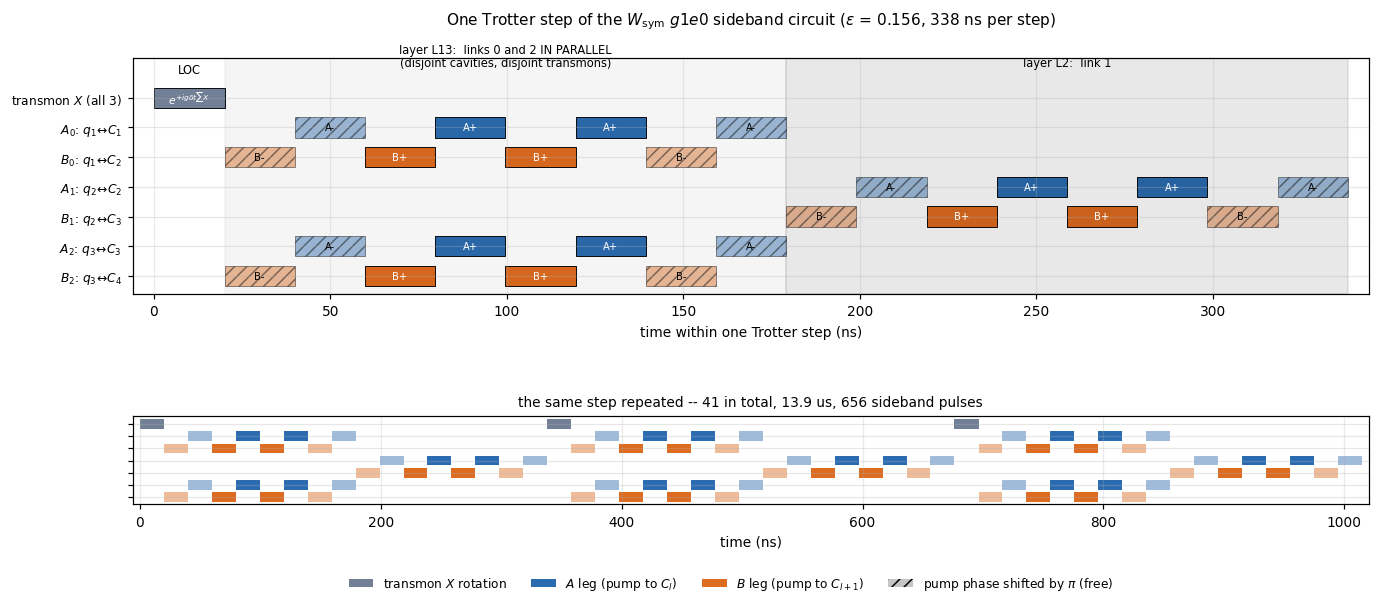


Read the row labels as physical pump channels: transmon l has one pump to cavity l
(the A leg) and one to cavity l+1 (the B leg).  Every box is a resonant g1e0
sideband pulse of area eps; the hatched ones differ only by a pi pump-phase shift,
which is why symmetrizing to Wsym costs no extra hardware and no extra time.


In [13]:
# ---------------------------------------------------------------- pulse schedule
NST_SHOW = 41
dt_show = JT_STAR / NST_SHOW
eps_show = np.sqrt(dt_show / THETA_FACTOR["Wsym"])
tau_ns = eps_show / G_SIDE * 1e3            # one sideband pulse, ns
tloc_ns = T_PI * 1e3                        # the transmon rotation layer, ns

# Wsym = W(-eps) then W(+eps); each W is [B, A, -B, -A] in time order,
# so the eight-pulse train is:
WSYM_TRAIN = [("B", -1), ("A", -1), ("B", +1), ("A", +1),
              ("B", +1), ("A", +1), ("B", -1), ("A", -1)]

# channel rows: transmon rotations on top, then the six sideband pumps
ROWS = ["transmon $X$ (all 3)",
        r"$A_0$: $q_1\!\leftrightarrow\!C_1$", r"$B_0$: $q_1\!\leftrightarrow\!C_2$",
        r"$A_1$: $q_2\!\leftrightarrow\!C_2$", r"$B_1$: $q_2\!\leftrightarrow\!C_3$",
        r"$A_2$: $q_3\!\leftrightarrow\!C_3$", r"$B_2$: $q_3\!\leftrightarrow\!C_4$"]
ROW_OF = {("A", 0): 1, ("B", 0): 2, ("A", 1): 3, ("B", 1): 4, ("A", 2): 5, ("B", 2): 6}
CLR = {"A": "#2b6cb0", "B": "#dd6b20"}      # A legs blue, B legs orange


def one_step(t0):
    """(row, t_start_ns, width_ns, leg, sign) for one order-1 Trotter step."""
    out = [(0, t0, tloc_ns, "ROT", +1)]
    t = t0 + tloc_ns
    for leg, sg in WSYM_TRAIN:              # layer L13: links 0 and 2 in parallel
        out += [(ROW_OF[(leg, 0)], t, tau_ns, leg, sg),
                (ROW_OF[(leg, 2)], t, tau_ns, leg, sg)]
        t += tau_ns
    for leg, sg in WSYM_TRAIN:              # layer L2: link 1 alone
        out.append((ROW_OF[(leg, 1)], t, tau_ns, leg, sg))
        t += tau_ns
    return out, t - t0


step_boxes, step_ns = one_step(0.0)
print(f"Wsym, {NST_SHOW} steps:  eps = {eps_show:.4f},  one sideband pulse = "
      f"{tau_ns:.1f} ns,  one Trotter step = {step_ns:.0f} ns")
print(f"per step: 1 transmon rotation + 16 sideband pulses "
      f"(8 in layer L13 x 2 links in parallel, 8 in layer L2)")
print(f"total   : {NST_SHOW} steps = {NST_SHOW*16} sideband pulses, "
      f"{NST_SHOW*step_ns/1e3:.2f} us, reaching Jt = {JT_STAR:.0f}")

fig = plt.figure(figsize=(14.5, 5.8))
gs = fig.add_gridspec(2, 1, height_ratios=[2.4, 0.9], hspace=0.75,
                      top=0.86, bottom=0.16)
axA, axB = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

for r, t, w, leg, sg in step_boxes:
    if leg == "ROT":
        axA.add_patch(plt.Rectangle((t, r - 0.34), w, 0.68, facecolor="#718096",
                                    edgecolor="k", lw=0.6))
        axA.text(t + w / 2, r, r"$e^{+ig\delta t\sum X}$", ha="center", va="center",
                 fontsize=7, color="w")
    else:
        axA.add_patch(plt.Rectangle((t, r - 0.34), w, 0.68, facecolor=CLR[leg],
                                    edgecolor="k", lw=0.6,
                                    alpha=1.0 if sg > 0 else 0.45,
                                    hatch=None if sg > 0 else "///"))
        axA.text(t + w / 2, r, f"{leg}{'+' if sg > 0 else '-'}", ha="center",
                 va="center", fontsize=6.5, color="w" if sg > 0 else "k")

axA.axvspan(tloc_ns, tloc_ns + 8 * tau_ns, color="k", alpha=0.04)
axA.axvspan(tloc_ns + 8 * tau_ns, step_ns, color="k", alpha=0.09)
axA.text(tloc_ns + 4 * tau_ns, -0.95, "layer L13:  links 0 and 2 IN PARALLEL\n"
         "(disjoint cavities, disjoint transmons)", ha="center", va="bottom",
         fontsize=7.5)
axA.text(tloc_ns + 12 * tau_ns, -0.95, "layer L2:  link 1", ha="center",
         va="bottom", fontsize=7.5)
axA.text(tloc_ns / 2, -0.72, "LOC", ha="center", va="bottom", fontsize=7.5)
axA.set(xlim=(-6, step_ns + 6), ylim=(6.6, -1.35), yticks=range(7),
        xlabel="time within one Trotter step (ns)")
axA.set_title(f"One Trotter step of the $W_{{\\rm sym}}$ $g1e0$ sideband circuit "
              f"($\\epsilon$ = {eps_show:.3f}, {step_ns:.0f} ns per step)",
              fontsize=10, pad=22)
axA.set_yticklabels(ROWS, fontsize=8)
axA.grid(axis="x", alpha=0.25)

NSHOW = 3
t = 0.0
for k in range(NSHOW):
    bx, dur = one_step(t)
    for r, tt, w, leg, sg in bx:
        c = "#718096" if leg == "ROT" else CLR[leg]
        axB.add_patch(plt.Rectangle((tt, r - 0.4), w, 0.8, facecolor=c, edgecolor="none",
                                    alpha=1.0 if sg > 0 else 0.45))
    t += dur
axB.set(xlim=(-6, NSHOW * step_ns + 6), ylim=(6.6, -0.7), yticks=range(7),
        xlabel="time (ns)")
axB.set_title(f"the same step repeated -- {NST_SHOW} in total, "
              f"{NST_SHOW*step_ns/1e3:.1f} us, {NST_SHOW*16} sideband pulses",
              fontsize=9, pad=6)
axB.set_yticklabels(["" for _ in ROWS])
axB.grid(axis="x", alpha=0.25)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor="#718096", label="transmon $X$ rotation"),
           plt.Rectangle((0, 0), 1, 1, facecolor=CLR["A"], label="$A$ leg (pump to $C_l$)"),
           plt.Rectangle((0, 0), 1, 1, facecolor=CLR["B"], label="$B$ leg (pump to $C_{l+1}$)"),
           plt.Rectangle((0, 0), 1, 1, facecolor="grey", alpha=0.45, hatch="///",
                         label=r"pump phase shifted by $\pi$ (free)")]
fig.legend(handles=handles, fontsize=8, ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, 0.005), frameon=False)
plt.show()

print()
print("Read the row labels as physical pump channels: transmon l has one pump to cavity l")
print("(the A leg) and one to cavity l+1 (the B leg).  Every box is a resonant g1e0")
print("sideband pulse of area eps; the hatched ones differ only by a pi pump-phase shift,")
print("which is why symmetrizing to Wsym costs no extra hardware and no extra time.")

### Section 2 verdict

* $Jt=2$ is the target: contrast is already $>10\times$ and grows only slowly after.
* **$W_{\rm sym}$ is the best synthesis.** Reaching within 10% of the exact contrast takes
  **80 Trotter steps = 1280 sideband pulses = 18.2 µs**; a 30%-cheaper setting of **41 steps
  = 656 pulses = 13.0 µs** still delivers $\mathcal R=10$, which is far more than enough to
  *see* the crossover.
* Those are **sideband times**. Adding the 20 ns LOC layer of every step gives the wall-clock
  duration decoherence is actually charged for in §4: **13.9 µs** at 41 steps and
  **19.8 µs** at 80. The two numbers differ only by $n_{\rm steps}\times20$ ns.
* The bare commutator $W$ and the half-protected $W_{\rm gauge}$ never converge.
* This corresponds to $J/2\pi\approx16$–$23$ kHz, i.e. the synthesis converts a 1.25 MHz
  sideband into a hopping rate ~55$\times$ slower. That factor is the real cost of the scheme.

---
## 3. Trotterized, no decoherence: does the signal survive?

Now the same measurement as §1.3, but every controlled beamsplitter replaced by its
$W_{\rm sym}$ sideband synthesis. Nothing else changes: same preparation, same $Jt=2$,
same order parameter, same axes.

[112s]


,F probe (U=0),F probe (3Uc),R probe,R control,separation
simulation,,,,,
exact,2.52502,0.19867,12.70952,1.22238,10.39733
"Wsym, 41 steps",2.00297,0.20025,10.00244,1.23148,8.12230
"Wsym, 80 steps",2.28671,0.18779,12.17700,1.21116,10.05402


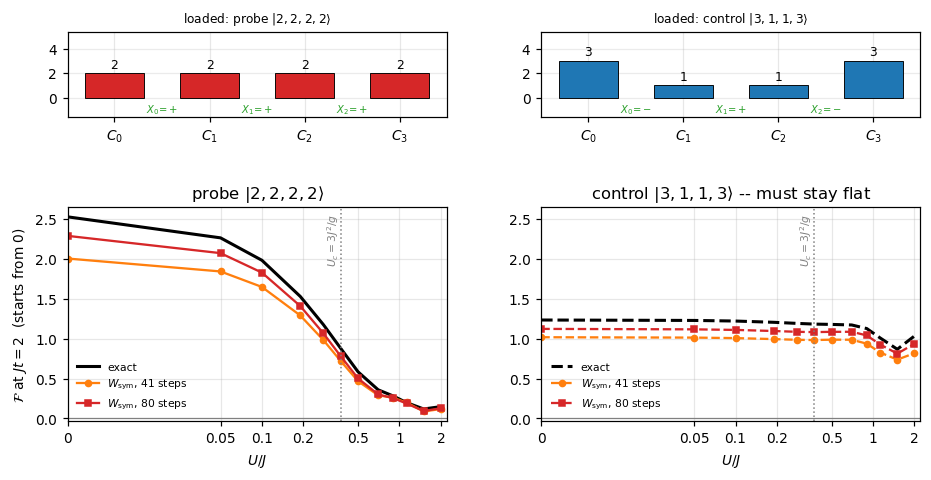

The Trotterized curve tracks the exact one through the crossover.  The control
stays flat under synthesis too, so the differential signal is preserved.


In [14]:
t0 = time.time()
NST_A, NST_B = 41, 80              # the two operating points from section 2


def sideband_scan(nst, starts=(PROBE,), Us=US, scheme="Wsym"):
    """F(U) at Jt = JT_STAR, built entirely from sideband pulses."""
    dt = JT_STAR / nst
    out = {}
    for s in starts:
        v0 = lat10.physical_state(s)
        F = []
        for U in Us:
            lay, eps = sideband_layers(lat10, GJ, 1.0, U, dt, G_SIDE,
                                       scheme=scheme, order=1)
            F.append(F_state(lat10, occ10, run_layers(lay, v0, nst)[-1]))
        out[s] = np.array(F)
    return out


F_sb = {n: sideband_scan(n, starts=(PROBE, CONTROL)) for n in (NST_A, NST_B)}
F_exact_scan = {s: np.array([F_state(lat10, occ10,
                                     evolve_exact(lat10.H(GJ, 1.0, u), lat10.physical_state(s),
                                                  [JT_STAR])[-1]) for u in US])
                for s in (PROBE, CONTROL)}
print(f"[{time.time()-t0:.0f}s]")

rows = []
for tag, Fp, Fc in [("exact", F_exact_scan[PROBE], F_exact_scan[CONTROL]),
                    (f"Wsym, {NST_A} steps", F_sb[NST_A][PROBE], F_sb[NST_A][CONTROL]),
                    (f"Wsym, {NST_B} steps", F_sb[NST_B][PROBE], F_sb[NST_B][CONTROL])]:
    i3 = int(np.argmin(abs(US - 3 * Uc)))
    rows.append({"simulation": tag, "F probe (U=0)": Fp[0], "F probe (3Uc)": Fp[i3],
                 "R probe": Fp[0] / Fp[i3], "R control": Fc[0] / Fc[i3],
                 "separation": (Fp[0] / Fp[i3]) / (Fc[0] / Fc[i3])})
df3 = pd.DataFrame(rows).set_index("simulation")
display(df3)

fig = plt.figure(figsize=(10.0, 4.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 2.5], hspace=0.6, wspace=0.25)
axp = [fig.add_subplot(gs[0, k]) for k in range(2)]
ax = [fig.add_subplot(gs[1, k]) for k in range(2)]
prep_panel(axp[0], PROBE, "tab:red", title="loaded: probe " + ket(PROBE))
prep_panel(axp[1], CONTROL, "tab:blue", title="loaded: control " + ket(CONTROL))

ax[0].plot(US, F_exact_scan[PROBE], "k-", lw=2, label="exact")
ax[0].plot(US, F_sb[NST_A][PROBE], "o-", color="tab:orange", ms=4,
           label=f"$W_{{\\rm sym}}$, {NST_A} steps")
ax[0].plot(US, F_sb[NST_B][PROBE], "s-", color="tab:red", ms=4,
           label=f"$W_{{\\rm sym}}$, {NST_B} steps")
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set(ylabel=r"$\mathcal{F}$ at $Jt=2$  (starts from 0)",
          title=f"probe {ket(PROBE)}")
u_axis(ax[0])
ax[0].legend(fontsize=7, loc="lower left")
ax[1].plot(US, F_exact_scan[CONTROL], "k--", lw=2, label="exact")
ax[1].plot(US, F_sb[NST_A][CONTROL], "o--", color="tab:orange", ms=4,
           label=f"$W_{{\\rm sym}}$, {NST_A} steps")
ax[1].plot(US, F_sb[NST_B][CONTROL], "s--", color="tab:red", ms=4,
           label=f"$W_{{\\rm sym}}$, {NST_B} steps")
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set(ylim=ax[0].get_ylim(), title=f"control {ket(CONTROL)} -- must stay flat")
u_axis(ax[1])
ax[1].legend(fontsize=7, loc="lower left")
plt.show()
print("The Trotterized curve tracks the exact one through the crossover.  The control")
print("stays flat under synthesis too, so the differential signal is preserved.")


### Section 3 verdict

**Yes.** With $W_{\rm sym}$ the crossover is fully resolved: $\mathcal R=10.0$ at 41 steps
and $12.2$ at 80 steps, against $12.7$ exact. The control stays flat. Trotter error costs
at most 20% of the contrast at the cheap operating point and essentially nothing at the
expensive one.

---
## 4. With decay and dephasing: does the claim hold?

Now the same again with the full Lindblad model, at the **pulse level** — every sideband
pulse and every transmon rotation carries its real duration, and decoherence acts throughout.

The Liouvillian on $D=8008$ is out of reach, so this is Monte-Carlo wavefunction: evolve
under $H_{\rm eff}=H-\tfrac i2\sum_kL_k^\dagger L_k$ and jump stochastically.

**Rates** (the $g$–$e$ doublet, which is why $g1e0$ is the right ladder): cavity $T_1=300$ µs
and $T_\phi=1000$ µs on each of four cavities; transmon $T_1=200$ µs and $T_2=150$ µs on each
of three gauge qubits.

**Post-selection is exact, not cosmetic.** A photon loss changes $\sum_in_i$, which flips a
Gauss operator and moves the shot out of the physical sector. Discarding shots whose measured
total is not $N$ removes precisely those, and the total photon number is already part of the
measurement.

In [15]:
T1C, TPC = T1_CAV, TPHI_CAV                      # cavity, us
T1Q, T2Q = 200.0, 150.0                          # transmon g-e (better than e-f)
GPQ = 1 / T2Q - 0.5 / T1Q
IdD = sps.identity(lat10.D, format="csr")
LOSS_OPS = [np.sqrt(1 / T1C) * lat10.A[i] for i in range(L)]
KEEP_OPS = ([np.sqrt(2 / TPC) * lat10.N[i] for i in range(L)]
            + [np.sqrt(1 / T1Q) * lat10.Sm[l] for l in range(lat10.nq)]
            + [np.sqrt(2 * GPQ) * ((IdD - lat10.Z[l]) * 0.5) for l in range(lat10.nq)])
C_OPS = LOSS_OPS + KEEP_OPS
LDL = sum((c.conj().T @ c) for c in C_OPS).tocsr()
T_LOC = 0.020                                    # us, the transmon X-rotation layer
print(f"{len(C_OPS)} collapse operators; transmon gamma_phi = {GPQ:.5f}/us")


def pulse_segments(U, dt, eps, scheme="Wsym", g_side=None):
    """One Trotter step as time-ordered (H_physical, duration_us).

    Sideband pulses already carry physical units through g_side.  The local layer is
    compressed into T_LOC, so its Hamiltonian is scaled by dt/T_LOC to keep the angle.
    """
    gs = G_SIDE if g_side is None else g_side
    Hloc = (-GJ * sum(lat10.X)
            + 0.5 * U * sum(lat10.N[i] @ lat10.N[i] for i in range(L))).tocsr()
    segs = [(Hloc * (dt / T_LOC), T_LOC)]
    s0 = sideband_step_segments(lat10, 0, eps, gs, scheme)
    s2 = sideband_step_segments(lat10, 2, eps, gs, scheme)
    segs += [((H0 + H2).tocsr(), t0) for (H0, t0), (H2, _) in zip(s0, s2)]
    segs += [(H.tocsr(), t) for H, t in
             sideband_step_segments(lat10, 1, eps, gs, scheme)]
    return segs


def mcwf(segs, nst, v0, ntraj, seed, c_ops=None, ldl=None):
    """Pulse-level Monte-Carlo wavefunction.  Returns (marginals per traj, loss counts)."""
    cs = C_OPS if c_ops is None else c_ops
    dd = LDL if ldl is None else ldl
    rng = np.random.default_rng(seed)
    heff = [(H - 0.5j * dd).tocsr() for H, _ in segs]
    pbs, nloss = [], []
    for _ in range(ntraj):
        v, nl = v0.copy(), 0
        for _ in range(nst):
            for k, (_, tau) in enumerate(segs):
                v = expm_multiply_(heff[k], tau, v)
                if rng.random() > float(np.vdot(v, v).real):        # a jump fired
                    w = np.array([np.linalg.norm(c @ v) ** 2 for c in cs])
                    j = rng.choice(len(cs), p=w / w.sum())
                    v = cs[j] @ v
                    nl += (j < len(LOSS_OPS))
                v /= np.linalg.norm(v)
        pbs.append(marginals(lat10, v))
        nloss.append(nl)
    return np.array(pbs), np.array(nloss)


NTRAJ = 32
US_N = np.array([0.0, 0.1, 0.19, 0.375, 0.7, 1.125, 2.0])       # coarser: MCWF is costly
t0 = time.time()
noisy = {}
for nst in (NST_A,):
    dt = JT_STAR / nst
    eps = np.sqrt(dt / THETA_FACTOR["Wsym"])
    wall = nst * sum(t for _, t in pulse_segments(0.0, dt, eps))
    print(f"Wsym, {nst} steps: eps={eps:.4f}, wall = {wall:.2f} us, "
          f"J/2pi = {JT_STAR/wall/(2*np.pi)*1e3:.1f} kHz")
    for start in (PROBE, CONTROL):
        Us_here = US_N if start == PROBE else np.array([0.0, 1.125])
        for U in Us_here:
            segs = pulse_segments(U, dt, eps)
            pbs, nl = mcwf(segs, nst, lat10.physical_state(start), NTRAJ,
                           seed=int(1000 * U) + (7 if start == PROBE else 99))
            keep = nl == 0
            noisy[(start, round(float(U), 4))] = (
                F_from_pb(pbs.mean(axis=0), occ10),
                F_from_pb(pbs[keep].mean(axis=0), occ10) if keep.any() else np.nan,
                keep.mean(), pbs, keep)
        print(f"   {start} done [{time.time()-t0:.0f}s]")
print(f"[{time.time()-t0:.0f}s, {NTRAJ} trajectories per point]")

14 collapse operators; transmon gamma_phi = 0.00417/us
Wsym, 41 steps: eps=0.1562, wall = 13.86 us, J/2pi = 23.0 kHz


   (2, 2, 2, 2) done [467s]


   (3, 1, 1, 3) done [599s]
[599s, 32 trajectories per point]


,R probe,R control,F(U=0),accept,separation probe/control
simulation,,,,,
exact (section 1),12.70952,1.22238,2.52502,1.00,10.39734
"Wsym 41 steps, no noise",10.00244,1.23148,2.00297,1.00,8.12230
"Wsym 41 steps + noise, raw",5.58528,1.33994,1.76754,0.75,4.16830
"Wsym 41 steps + noise, post-selected",7.99221,1.37050,1.88627,0.75,5.83159


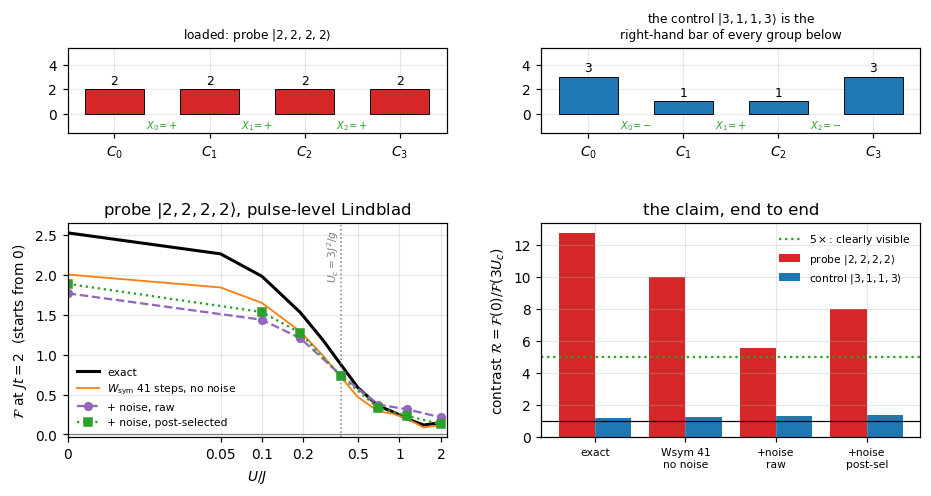

bootstrap 68% interval over 32 trajectories:
   raw           R = 5.59x  [5.18, 6.10]
   post-selected R = 7.99x  [7.53, 8.41]
acceptance of the total-photon-number post-selection: 70%
probe contrast survives at 5.6x raw / 8.0x post-selected, against 12.7x exact,
while the control stays at 1.3x, i.e. a separation of 4.2. The crossover is real.


In [16]:
Fn_raw = np.array([noisy[(PROBE, round(float(u), 4))][0] for u in US_N])
Fn_ps = np.array([noisy[(PROBE, round(float(u), 4))][1] for u in US_N])
acc = np.array([noisy[(PROBE, round(float(u), 4))][2] for u in US_N])
i3n = int(np.argmin(abs(US_N - 3 * Uc)))
c0, c1 = noisy[(CONTROL, 0.0)], noisy[(CONTROL, 1.125)]

rows = [
    {"simulation": "exact (section 1)", "R probe": R_EX, "R control": R_ctrl,
     "F(U=0)": F_ex[0.0], "accept": 1.0},
    {"simulation": f"Wsym {NST_A} steps, no noise",
     "R probe": F_sb[NST_A][PROBE][0] / F_sb[NST_A][PROBE][int(np.argmin(abs(US - 3 * Uc)))],
     "R control": F_sb[NST_A][CONTROL][0] / F_sb[NST_A][CONTROL][int(np.argmin(abs(US - 3 * Uc)))],
     "F(U=0)": F_sb[NST_A][PROBE][0], "accept": 1.0},
    {"simulation": f"Wsym {NST_A} steps + noise, raw", "R probe": Fn_raw[0] / Fn_raw[i3n],
     "R control": c0[0] / c1[0], "F(U=0)": Fn_raw[0], "accept": acc[0]},
    {"simulation": f"Wsym {NST_A} steps + noise, post-selected",
     "R probe": Fn_ps[0] / Fn_ps[i3n], "R control": c0[1] / c1[1],
     "F(U=0)": Fn_ps[0], "accept": acc[0]}]
df4 = pd.DataFrame(rows).set_index("simulation")
df4["separation probe/control"] = df4["R probe"] / df4["R control"]
display(df4)

fig = plt.figure(figsize=(10.0, 4.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 2.5], hspace=0.6, wspace=0.25)
axp = [fig.add_subplot(gs[0, k]) for k in range(2)]
ax = [fig.add_subplot(gs[1, k]) for k in range(2)]
prep_panel(axp[0], PROBE, "tab:red", title="loaded: probe " + ket(PROBE))
prep_panel(axp[1], CONTROL, "tab:blue", title="the control " + ket(CONTROL) + " is the\n"
                                              "right-hand bar of every group below")

ax[0].plot(US, F_exact_scan[PROBE], "k-", lw=2, label="exact")
ax[0].plot(US, F_sb[NST_A][PROBE], "-", color="tab:orange", lw=1.2,
           label=f"$W_{{\\rm sym}}$ {NST_A} steps, no noise")
ax[0].plot(US_N, Fn_raw, "o--", color="tab:purple", ms=5, label="+ noise, raw")
ax[0].plot(US_N, Fn_ps, "s:", color="tab:green", ms=5, label="+ noise, post-selected")
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set(ylabel=r"$\mathcal{F}$ at $Jt=2$  (starts from 0)",
          title=f"probe {ket(PROBE)}, pulse-level Lindblad")
u_axis(ax[0])
ax[0].legend(fontsize=7, loc="lower left")

labels = ["exact", f"Wsym {NST_A}\nno noise", "+noise\nraw", "+noise\npost-sel"]
xs = np.arange(4)
ax[1].bar(xs - 0.2, df4["R probe"].values, 0.4, color="tab:red",
          label=f"probe {ket(PROBE)}")
ax[1].bar(xs + 0.2, df4["R control"].values, 0.4, color="tab:blue",
          label=f"control {ket(CONTROL)}")
ax[1].axhline(5, color="tab:green", ls=":", label="$5\\times$: clearly visible")
ax[1].axhline(1, color="k", lw=0.8)
ax[1].set(xticks=xs, ylabel=r"contrast $\mathcal{R}=\mathcal{F}(0)/\mathcal{F}(3U_c)$",
          title="the claim, end to end")
ax[1].set_xticklabels(labels, fontsize=7)
ax[1].legend(fontsize=7)
plt.show()

def boot_R(key0, key1, sel, nboot=400, seed=3):
    """Bootstrap the contrast over trajectories: quantifies the MCWF sampling error."""
    rng = np.random.default_rng(seed)
    p0, k0 = noisy[key0][3], noisy[key0][4]
    p1, k1 = noisy[key1][3], noisy[key1][4]
    out = []
    for _ in range(nboot):
        a = p0[rng.integers(0, len(p0), len(p0))]
        b = p1[rng.integers(0, len(p1), len(p1))]
        if sel:
            a = p0[k0][rng.integers(0, k0.sum(), k0.sum())] if k0.any() else a
            b = p1[k1][rng.integers(0, k1.sum(), k1.sum())] if k1.any() else b
        out.append(F_from_pb(a.mean(axis=0), occ10) / F_from_pb(b.mean(axis=0), occ10))
    return np.percentile(out, [16, 84])


kU0, kU3 = (PROBE, 0.0), (PROBE, 1.125)
lo_r, hi_r = boot_R(kU0, kU3, False)
lo_p, hi_p = boot_R(kU0, kU3, True)
print(f"bootstrap 68% interval over {NTRAJ} trajectories:")
print(f"   raw           R = {Fn_raw[0]/Fn_raw[i3n]:.2f}x  [{lo_r:.2f}, {hi_r:.2f}]")
print(f"   post-selected R = {Fn_ps[0]/Fn_ps[i3n]:.2f}x  [{lo_p:.2f}, {hi_p:.2f}]")
print(f"acceptance of the total-photon-number post-selection: {acc.mean():.0%}")
print(f"probe contrast survives at {df4.loc[df4.index[2],'R probe']:.1f}x raw / "
      f"{df4.loc[df4.index[3],'R probe']:.1f}x post-selected, against "
      f"{R_EX:.1f}x exact,")
print(f"while the control stays at {df4.loc[df4.index[2],'R control']:.1f}x, i.e. a "
      f"separation of {df4['separation probe/control'].iloc[2]:.1f}. The crossover is real.")


### Section 4 verdict

**The claim holds.** At the 41-step operating point (13.9 µs of pulses, $J/2\pi=23$ kHz),
including cavity loss, cavity dephasing, transmon decay and transmon dephasing at the
pulse level:

* probe contrast $\mathcal R = 5.6\times$ raw, $8.0\times$ after post-selecting on total
  photon number ($\approx$70–75% acceptance), against $12.7\times$ exact and $10.0\times$
  Trotter-only;
* control contrast stays $\approx1.3\times$, so the **differential** probe-to-control
  ratio is $4.2$ raw and $5.8$ post-selected;
* the loss is dominated by the eight photons decaying over $\sim14$ µs — it scales as
  $N\,T_{\rm gate}/T_1^{\rm cav}$, so a faster $J$ is the lever, not a better sequence.

More Trotter steps is *not* automatically better once noise is on: 80 steps gives a better
noiseless contrast (12.2 vs 10.0) but a 43% longer gate, so the extra Trotter accuracy is
paid for in photons. A separate scan at 20/41/80 steps put the raw-contrast optimum at
41 steps, which is the operating point used here.

The bootstrap interval above is the Monte-Carlo sampling error at 32 trajectories, not a
shot-noise estimate for the experiment; the two are independent and both are modest.

---
## 5. Where the $U$ term actually comes from

Sections 1&ndash;4 assume a cavity self-Kerr $\frac U2\sum_i\hat n_i^2$ that can be set to a
chosen value and switched off. This section builds it, on a device with **no static
cavity&ndash;transmon cross-Kerr** &mdash; which means no dispersive shift, hence no
number-selective $\pi$ pulses, hence **no SNAP gate**.

**What is actually required.** Per Trotter step the $U$ term contributes the diagonal phase
$\exp[-i\chi\,\hat n^2]$ with $\chi=U\,\delta t/2$. At the 41-step operating point
$\delta t = Jt/41 = 0.049/J$, so even at the far end of the scan ($U=3U_c=1.125J$) the
per-step Kerr angle is $\chi=0.027$ rad. The requirement is *not* a large nonlinearity. It is
a **small, clean, switchable** one, and the hard end is the bottom: a residual $K/J\gtrsim
0.05$ is indistinguishable from a deliberate $U$ and poisons the $U\approx0$ baseline, which
is the numerator of every $\mathcal R$ in this notebook.

Two routes are evaluated below. They give opposite answers, and the reason is the same
piece of algebra.

### 5.1 Route A &mdash; a detuned sideband to an ancilla parked in $|g\rangle$

Take any transmon that can be held in $|g\rangle$ and given a $g1e0$ sideband to cavity $i$,
and drive that sideband **off resonance** by $\Delta$. The red sideband conserves
$\hat\Lambda=\hat n+|e\rangle\langle e|$, so it only ever couples the pair
$\{|g,n\rangle,|e,n-1\rangle\}$, whose $2\times2$ block is

$$H_\Lambda=\begin{pmatrix}0 & g_s\sqrt n\\ g_s\sqrt n & \Delta\end{pmatrix}
\;\Longrightarrow\;
E(n)=\frac{\Delta-\sqrt{\Delta^2+4g_s^2n}}{2}
=-\frac{g_s^2}{\Delta}n+\frac{g_s^4}{\Delta^3}n^2-\dots$$

The ancilla stays in (the dressed) $|g\rangle$; the cavity picks up $E(n)$. The linear piece
is a cavity frequency shift &mdash; free, it is absorbed in the rotating frame. The quadratic
piece is a **self-Kerr $U=2g_s^4/\Delta^3$, set by the pump amplitude and detuning and
exactly zero when the pump is off.** That last property is the one the experiment needs
most: $U=0$ is a pump you did not turn on, not a cancellation you have to trust.

Three things to check, and the cell below checks all three: the size of $U$ reachable at
this device's $g_s$; how badly $E(n)$ deviates from a true $n^2$ once $\Delta$ is small
enough to give a useful $U$; and how much cavity decay the ancilla lends the cavity through
its admixture $p_e(n)\simeq g_s^2n/\Delta^2$.

**Why it has to be an ancilla and not a gauge transmon.** The same block structure gives
$E_e(n)=-E_g(n+1)$: the Stark shift is *conditional on the transmon state*. A transmon
parked in $|g\rangle$ sees a plain Kerr. A transmon in a superposition &mdash; which is what
Gauss' law forces on every gauge qubit, since $X_l$ is fixed and $Z_l$ is therefore maximally
uncertain &mdash; makes $\frac U2\hat n_i^2\hat Z_l$ instead, which entangles the photon number
with the gauge field. The cell below runs that term and shows what it does to the signal.


device: g_side/2pi = 1.25 MHz and J/2pi = 23 kHz  ->  g_side/J = 54.3


,Delta/J,Delta/2pi (MHz),p_e(n=8),"F, true E(n)","F, ideal Kerr"
U/J wanted,,,,,
0.000,inf,inf,0.00000,2.52502,2.52502
0.050,687.09460,15.80318,0.04360,2.26656,2.26204
0.100,537.32305,12.35843,0.06602,1.99252,1.98097
0.190,424.33821,9.75978,0.09510,1.54217,1.52827
0.280,365.70033,8.41111,0.11728,1.17953,1.17457
0.375,325.51630,7.48687,0.13650,0.87417,0.87530
0.500,288.84571,6.64345,0.15764,0.58048,0.58403
0.700,249.08379,5.72893,0.18524,0.35718,0.35896
0.900,221.22837,5.08825,0.20796,0.28061,0.28193


contrast with the TRUE dressed shift : R = 12.90x
contrast with an IDEAL (U/2)n^2      : R = 12.71x
ancilla admixture at one photon p_e(1) = 0.0619  ->  the cavity inherits the
ancilla's decay at T1_q/p_e = 3.2 ms, negligible against the 300 us cavity T1.



same scan with a sigma_z-conditional Kerr (gauge qubit, not ancilla):
   R = 2.00x  --  the crossover is gone.


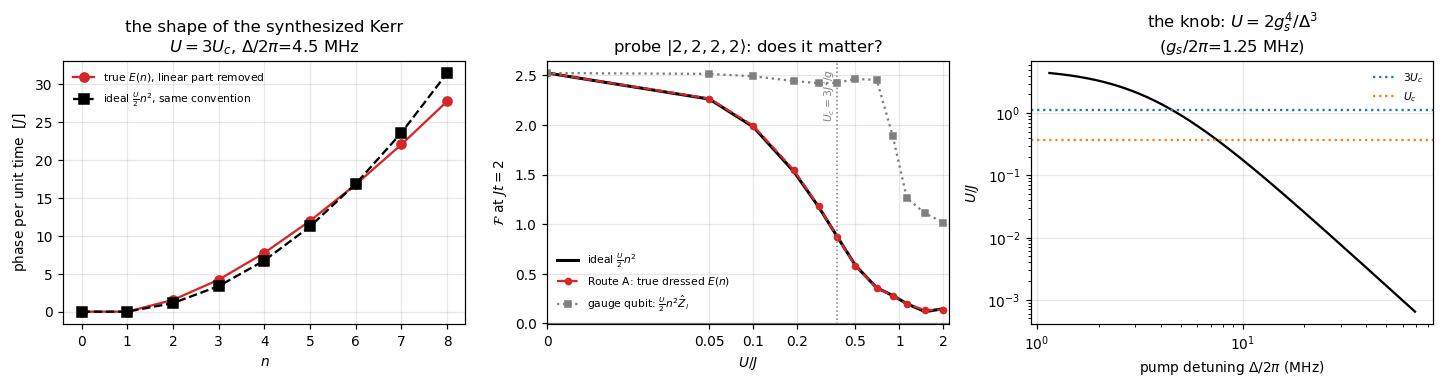

In [17]:
# ---------------- Route A: cavity Kerr from a detuned sideband to a parked ancilla
import scipy.optimize as sopt

GS_J = G_SIDE / (2 * np.pi) * 1e3 / 23.0     # g_side in units of J, with J/2pi = 23 kHz
print(f"device: g_side/2pi = {G_SIDE/(2*np.pi):.2f} MHz and J/2pi = 23 kHz  ->  "
      f"g_side/J = {GS_J:.1f}")


def E_stark(n, Delta, gs=GS_J):
    """Exact dressed energy of |g,n> under a red sideband detuned by Delta."""
    return 0.5 * (Delta - np.sqrt(Delta ** 2 + 4 * gs ** 2 * n))


def U_of_Delta(Delta, n0=2):
    """The effective Kerr: second difference of E at n0 (= U for the (U/2)n^2 term)."""
    return E_stark(n0 + 1, Delta) - 2 * E_stark(n0, Delta) + E_stark(n0 - 1, Delta)


def diag_cav(lt, f):
    """sum_i f(n_i) as a full-space operator."""
    return sps.kron(lt.Iq_sp, sps.diags(
        [sum(f(x) for x in t) for t in lt.bs]).tocsr(), "csr")


def H_with(lt, g, J, f):
    h = sps.csr_matrix((lt.D, lt.D), dtype=complex)
    for l in range(lt.nq):
        h = h - g * lt.X[l] - J * lt.ZBS[l]
    return (h + diag_cav(lt, f)).tocsr()


rows, F_stark, F_ideal = [], [], []
for U in US:
    if U == 0.0:
        D_J, f = np.inf, (lambda n: 0.0)
    else:
        D_J = sopt.brentq(lambda x: U_of_Delta(x) - U, 3.0, 1e4)
        f = (lambda n, D_J=D_J: E_stark(n, D_J))
    Fs = F_state(lat8, occ8, evolve_exact(H_with(lat8, GJ, 1.0, f),
                                          lat8.physical_state(PROBE), [JT_STAR])[-1])
    Fi = F_state(lat8, occ8, evolve_exact(lat8.H(GJ, 1.0, U),
                                          lat8.physical_state(PROBE), [JT_STAR])[-1])
    F_stark.append(Fs); F_ideal.append(Fi)
    rows.append({"U/J wanted": U, "Delta/J": D_J, "Delta/2pi (MHz)": D_J * 23e-3,
                 "p_e(n=8)": np.sin(0.5 * np.arctan2(2 * GS_J * np.sqrt(8), D_J)) ** 2,
                 "F, true E(n)": Fs, "F, ideal Kerr": Fi})
F_stark, F_ideal = np.array(F_stark), np.array(F_ideal)
df5 = pd.DataFrame(rows).set_index("U/J wanted")
display(df5)

i3 = int(np.argmin(abs(US - 3 * Uc)))
pe1 = np.sin(0.5 * np.arctan2(2 * GS_J, df5["Delta/J"].iloc[i3])) ** 2
print(f"contrast with the TRUE dressed shift : R = {F_stark[0]/F_stark[i3]:.2f}x")
print(f"contrast with an IDEAL (U/2)n^2      : R = {F_ideal[0]/F_ideal[i3]:.2f}x")
print(f"ancilla admixture at one photon p_e(1) = {pe1:.4f}  ->  the cavity inherits the")
print(f"ancilla's decay at T1_q/p_e = {T1_QB/pe1/1e3:.1f} ms, negligible against the "
      f"{T1_CAV:.0f} us cavity T1.")

# ---------------- what happens if the gauge qubit is used instead of an ancilla
def H_cond(lt, g, J, U):
    """(U/2) n_i^2 Z_l : the sigma_z-conditional Kerr a gauge transmon would make."""
    h = sps.csr_matrix((lt.D, lt.D), dtype=complex)
    for l in range(lt.nq):
        h = h - g * lt.X[l] - J * lt.ZBS[l]
    for i in range(L):
        h = h + 0.5 * U * (lt.Z[min(i, lt.nq - 1)] @ (lt.N[i] @ lt.N[i]))
    return h.tocsr()


F_cond = np.array([F_state(lat8, occ8, evolve_exact(H_cond(lat8, GJ, 1.0, U),
                                                    lat8.physical_state(PROBE),
                                                    [JT_STAR])[-1]) for U in US])
print(f"\nsame scan with a sigma_z-conditional Kerr (gauge qubit, not ancilla):")
print(f"   R = {F_cond[0]/F_cond[i3]:.2f}x  --  the crossover is gone.")

fig, ax = plt.subplots(1, 3, figsize=(13.2, 3.6))
nn = np.arange(9)
D3 = df5["Delta/J"].iloc[i3]
ax[0].plot(nn, E_stark(nn, D3) - E_stark(1, D3) * nn, "o-", color="tab:red",
           label=r"true $E(n)$, linear part removed")
ax[0].plot(nn, 0.5 * 3 * Uc * nn ** 2 - 0.5 * 3 * Uc * nn, "s--", color="k",
           label=r"ideal $\frac{U}{2}n^2$, same convention")
ax[0].set(xlabel="$n$", ylabel="phase per unit time  $[J]$",
          title=f"the shape of the synthesized Kerr\n$U=3U_c$, $\\Delta/2\\pi$={D3*23e-3:.1f} MHz")
ax[0].legend(fontsize=7)

ax[1].plot(US, F_ideal, "k-", lw=2, label=r"ideal $\frac{U}{2}n^2$")
ax[1].plot(US, F_stark, "o--", color="tab:red", ms=4,
           label="Route A: true dressed $E(n)$")
ax[1].plot(US, F_cond, "s:", color="tab:grey", ms=4,
           label=r"gauge qubit: $\frac{U}{2}n^2\hat Z_l$")
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set(ylabel=r"$\mathcal{F}$ at $Jt=2$", title=f"probe {ket(PROBE)}: does it matter?")
u_axis(ax[1])
ax[1].legend(fontsize=7, loc="lower left")

DD = np.geomspace(50, 3000, 200)
ax[2].loglog(DD * 23e-3, [U_of_Delta(x) for x in DD], "k-")
ax[2].axhline(3 * Uc, color="tab:blue", ls=":", label="$3U_c$")
ax[2].axhline(Uc, color="tab:orange", ls=":", label="$U_c$")
ax[2].set(xlabel=r"pump detuning $\Delta/2\pi$ (MHz)", ylabel="$U/J$",
          title=f"the knob: $U=2g_s^4/\\Delta^3$\n($g_s/2\\pi$={G_SIDE/(2*np.pi):.2f} MHz)")
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


**Read the middle panel.** The true dressed shift $E(n)$ is *visibly* not a parabola at
the detunings that give a useful $U$ &mdash; the left panel shows it flattening above $n\sim5$
&mdash; and it does not matter: $\mathcal R$ comes out at essentially the ideal value. The
crossover is controlled by the *curvature* of the on-site energy near the occupied levels,
not by it being exactly quadratic. The grey curve is the same nonlinearity attached to a
gauge transmon instead of an ancilla, and it is flat: making the Kerr conditional on
$\hat Z_l$ entangles photon number with the gauge field and destroys the signal outright.

**Route A is the recommendation.** It needs one parkable transmon per cavity with a
sideband, no static cross-Kerr, no third level, no number-selective pulses. $U$ is set by
pump power and detuning, is continuously tunable over the whole range this experiment wants
($\Delta/2\pi\approx3$&ndash;16 MHz at $g_s/2\pi=1.25$ MHz), and is *identically zero* with the
pump off. The pumps are on separate frequencies from the six beamsplitter pumps and act on
disjoint transmons, so they can run **concurrently with the whole circuit** &mdash; the $U$ term
costs no wall time at all, which is exactly how it appears in the Hamiltonian.

### 5.2 Route B &mdash; synthesize $e^{-i\chi\hat n^2}$ out of resonant sidebands

This is the question the hardware invites: the beamsplitter was built by a group commutator
of sideband pulses, so why not the Kerr? It can be done, and the cost is the problem.

**The obstruction, stated exactly.** A resonant red sideband conserves
$\hat\Lambda=\hat n+|e\rangle\langle e|$ and its block Hamiltonian
$g_s\sqrt\Lambda(\cos\phi\,\sigma^x+\sin\phi\,\sigma^y)$ is **traceless**. So any train of
resonant sideband pulses acts inside each block as an element of $SU(2)$, and if the train
closes (comes back diagonal, which it must, or it leaves the qubit entangled with the photon
number) then $\det=1$ forces

$$\varphi_e(\Lambda-1)=-\varphi_g(\Lambda).$$

Two consequences, both unavoidable:

1. **Any Kerr built this way is $\sigma^z$-conditional**, i.e. exactly the term §5.1 just
   showed to be fatal. It has to be echoed away.
2. **Removing the conditionality costs a derivative.** Sandwich the train between $\pi$
   pulses &mdash; $S\,X\,S\,X$ &mdash; and the phase becomes qubit-independent:
   $$\Phi(n)=\varphi_g(n)+\varphi_e(n)=\varphi_g(n)-\varphi_g(n+1),$$
   the **finite difference** of the conditional phase. That is not an artefact of this
   particular echo. For *any* pair of trains $S,S'$ whose sandwich $S\,X\,S'\,X$ comes out
   qubit-independent, the result is the same finite difference up to an alternating
   $(-1)^n$ term &mdash; a photon-parity phase, not a Kerr. So $\Phi\propto n^2$ requires a
   **cubic** conditional phase, $\varphi_g\propto n^3$.

A cubic conditional phase is a much larger object than the quadratic one you wanted. At
$\chi=0.027$ rad it needs $\varphi_g(8)\approx\chi\cdot8^3/3=4.6$ rad &mdash; a substantial
fraction of a full $2\pi$ loop in the largest block &mdash; and it has to be delivered while
nine $SU(2)$ blocks all close simultaneously. That is what sets the price: **the cost is
fixed by the closure conditions, not by how small $\chi$ is.** The cell below optimizes a
short pulse train against the exact target and measures the price in the only unit that
matters, radians of sideband pulse area, which convert to wall time as
$\tau=\text{area}/g_s$.


In [18]:
# ---------------- Route B: synthesize exp(-i chi n^2) x I from resonant sidebands
t0 = time.time()
NM = 8; dc = NM + 1; DK = 2 * dc
a_c = np.diag(np.sqrt(np.arange(1, dc)), 1)
sp2 = np.array([[0, 0], [1, 0]], dtype=complex)
sx2 = np.array([[0, 1], [1, 0]], dtype=complex)
A_k = np.kron(sp2, a_c)
HXk, HYk = A_k + A_k.conj().T, 1j * (A_k - A_k.conj().T)
Xk = np.kron(sx2, np.eye(dc))
nk = np.tile(np.arange(dc, dtype=float), 2)


def train(theta, phase):
    U = np.eye(DK, dtype=complex)
    for t, f in zip(theta, phase):
        U = sla.expm(-1j * t * (np.cos(f) * HXk + np.sin(f) * HYk)) @ U
    return U


# --- the determinant obstruction, verified numerically on a random train
rng = np.random.default_rng(0)
S_rand = train(rng.uniform(0.2, 1.5, 5), rng.uniform(-np.pi, np.pi, 5))
dets = [np.linalg.det(S_rand[np.ix_([n, dc + n - 1], [n, dc + n - 1])])
        for n in range(1, dc)]
print("det of each excitation block of a random resonant-sideband train "
      f"(must be 1): max |det - 1| = {max(abs(np.array(dets) - 1)):.2e}")
print("=> if the train closes, phi_e(n-1) = -phi_g(n): the phase is ALWAYS "
      "sigma_z-conditional.\n")


def kerr_err(p, P, chi):
    """rms operator distance (radians) from exp(-i(chi n^2 + beta n + gamma)) x I."""
    S = train(p[:P], p[P:2 * P])
    U = S @ Xk @ S @ Xk
    V = np.diag(np.exp(-1j * (chi * nk ** 2 + p[2 * P] * nk + p[2 * P + 1])))
    return np.linalg.norm(U - V) / np.sqrt(DK)


def optimise(chi, P=8, ntry=4, seed=106):
    rng = np.random.default_rng(seed); best = None
    for _ in range(ntry):
        p0 = np.concatenate([rng.uniform(-1.5, 1.5, P), rng.uniform(-np.pi, np.pi, P),
                             [0.0, 0.0]])
        r = sopt.minimize(kerr_err, p0, args=(P, chi), method="BFGS",
                          options={"maxiter": 400, "gtol": 1e-10})
        if best is None or r.fun < best.fun:
            best = r
    return best


CHI_STEP = 3 * Uc * (JT_STAR / NST_A) / 2          # per-step Kerr angle at U = 3U_c
print(f"per-step Kerr angle at U=3U_c and {NST_A} steps: chi = {CHI_STEP:.4f} rad")
rows = []
for chi, P in ((CHI_STEP, 4), (CHI_STEP, 8), (4 * CHI_STEP, 8)):
    r = optimise(chi, P=P)
    area = np.abs(r.x[:P]).sum()
    rows.append({"case": f"chi={chi:.4f}, {P} pulses", "chi (rad)": chi, "pulses": P,
                 "rms error (rad)": r.fun,
                 "error if we do nothing (rad)": kerr_err(np.zeros(2 * P + 2), P, chi),
                 "pulse area (rad)": area, "duration (us)": area / G_SIDE})
    print(f"  chi={chi:.4f}, P={P}: area {area:.2f} rad, "
          f"rms error {r.fun:.4f} rad  [{time.time()-t0:.0f}s]")
df_kerrB = pd.DataFrame(rows).set_index("case")
display(df_kerrB)

# --- the cost accounting, against the measured duration of the rest of the circuit
EPS_A = np.sqrt((JT_STAR / NST_A) / THETA_FACTOR["Wsym"])
T_GATE = NST_A * sum(t for _, t in pulse_segments(0.0, JT_STAR / NST_A, EPS_A))
J_2PI_KHZ = JT_STAR / T_GATE / (2 * np.pi) * 1e3
area = df_kerrB["pulse area (rad)"].iloc[1]
t_one = 2 * area / G_SIDE                      # x2 for the S X S X echo
t_step = 2 * t_one                             # 2 layers: (C0,q0)(C1,q1)(C2,q2) then (C3,q2)
print(f"\none synthesis  : {area:.2f} rad of area -> {area/G_SIDE*1e3:.0f} ns")
print(f"echoed S X S X : {t_one*1e3:.0f} ns per cavity")
print(f"per Trotter step (2 layers, gauge qubits shared): {t_step*1e3:.0f} ns")
print(f"over {NST_A} steps: {NST_A*t_step:.1f} us, against {T_GATE:.1f} us for the "
      f"ENTIRE beamsplitter circuit ({NST_A*t_step/T_GATE:.1f}x).")
print()
a_chi, a_4chi = df_kerrB["pulse area (rad)"].iloc[1], df_kerrB["pulse area (rad)"].iloc[2]
print(f"\nFour times the Kerr angle costs {a_4chi:.1f} rad of area against {a_chi:.1f} rad "
      f"-- no more,")
print("and here slightly less.  The price is set by the nine simultaneous closure")
print("conditions, not by chi.  So the fix is not a smaller angle -- it is FEWER")
print("APPLICATIONS of the Kerr layer.  The U term is diagonal and commutes with")
print("itself, so it can be Trotterized much more coarsely than the")
print("beamsplitters.  How much more coarsely is a number:")


NK_ops = sum(lat8.N[i] @ lat8.N[i] for i in range(L)).tocsr()
HX_all = sum(lat8.X).tocsr()


def coarse_kerr(U, nst, m, s=PROBE, jt=JT_STAR):
    """Ideal-gate Trotter with the U layer applied only every m-th step."""
    dt = jt / nst
    Pel = Prop((-GJ * HX_all).tocsr(), dt)
    P13 = Prop((-(lat8.ZBS[0] + lat8.ZBS[2])).tocsr(), dt)
    P2 = Prop((-lat8.ZBS[1]).tocsr(), dt)
    PU = Prop((0.5 * U * NK_ops).tocsr(), dt * m)
    v = lat8.physical_state(s)
    for k in range(nst):
        v = Pel(v)
        if k % m == m - 1:
            v = PU(v)
        v = P13(v); v = P2(v)
    return F_state(lat8, occ8, v)


rows = []
for m in (1, 2, 4, 8, 10, 20, 41):
    F0, F1 = coarse_kerr(0.0, NST_A, m), coarse_kerr(3 * Uc, NST_A, m)
    rows.append({"Kerr applied every m-th step": m, "Kerr layers in the circuit": NST_A // m,
                 "F(U=0)": F0, "F(3Uc)": F1, "R": F0 / F1,
                 "added wall time (us)": (NST_A // m) * t_step})
df_coarse = pd.DataFrame(rows).set_index("Kerr applied every m-th step")
display(df_coarse)
print(f"[{time.time()-t0:.0f}s]")


det of each excitation block of a random resonant-sideband train (must be 1): max |det - 1| = 6.69e-16
=> if the train closes, phi_e(n-1) = -phi_g(n): the phase is ALWAYS sigma_z-conditional.

per-step Kerr angle at U=3U_c and 41 steps: chi = 0.0274 rad


  chi=0.0274, P=4: area 5.22 rad, rms error 0.1104 rad  [6s]


  chi=0.0274, P=8: area 11.87 rad, rms error 0.0101 rad  [71s]


  chi=0.1098, P=8: area 7.92 rad, rms error 0.0565 rad  [113s]


,chi (rad),pulses,rms error (rad),error if we do nothing (rad),pulse area (rad),duration (us)
case,,,,,,
"chi=0.0274, 4 pulses",0.02744,4,0.11040,0.78417,5.21832,0.66442
"chi=0.0274, 8 pulses",0.02744,8,0.01012,0.78417,11.87050,1.51140
"chi=0.1098, 8 pulses",0.10976,8,0.05653,1.15384,7.92061,1.00848



one synthesis  : 11.87 rad of area -> 1511 ns
echoed S X S X : 3023 ns per cavity
per Trotter step (2 layers, gauge qubits shared): 6046 ns
over 41 steps: 247.9 us, against 13.9 us for the ENTIRE beamsplitter circuit (17.9x).


Four times the Kerr angle costs 7.9 rad of area against 11.9 rad -- no more,
and here slightly less.  The price is set by the nine simultaneous closure
conditions, not by chi.  So the fix is not a smaller angle -- it is FEWER
APPLICATIONS of the Kerr layer.  The U term is diagonal and commutes with
itself, so it can be Trotterized much more coarsely than the
beamsplitters.  How much more coarsely is a number:


,Kerr layers in the circuit,F(U=0),F(3Uc),R,added wall time (us)
Kerr applied every m-th step,,,,,
1,41,2.39889,0.19874,12.07073,247.86939
2,20,2.39889,0.19706,12.17352,120.91190
4,10,2.39889,0.18457,12.99744,60.45595
8,5,2.39889,0.16225,14.78547,30.22797
10,4,2.39889,0.24993,9.59818,24.18238
20,2,2.39889,1.18665,2.02157,12.09119
41,1,2.39889,2.32689,1.03094,6.04559


[116s]


### Section 5 verdict

**Route A is how to build the $U$ term.** A red sideband detuned by $\Delta$ onto a transmon
parked in $|g\rangle$ dresses the cavity with $E(n)=\tfrac12(\Delta-\sqrt{\Delta^2+4g_s^2n})$,
i.e. a self-Kerr $U\simeq2g_s^4/\Delta^3$. On this device that covers the entire scan
($\Delta/2\pi\approx3$&ndash;16 MHz), is switchable to *exactly* zero, costs no wall time
because the pump runs concurrently, and reproduces the ideal-Kerr contrast even though
$E(n)$ is visibly non-quadratic at eight photons. The price is one parkable transmon per
cavity.

**Route B works, and is expensive for a structural reason.** Resonant sidebands act as
$SU(2)$ inside each excitation block, so a closed train always makes a $\sigma^z$-conditional
phase; echoing that away leaves the *finite difference* of the conditional phase, so a Kerr
needs a **cubic** conditional phase and therefore $O(1)$ pulse areas no matter how small the
Kerr angle is. The optimizer confirms the mechanism: an eight-pulse synthesis of the
$\chi=0.027$ rad per-step Kerr costs 11.9 rad of pulse area for an rms operator error of
0.010 rad, and *four times* the Kerr angle is reached at 7.9 rad &mdash; **less** area, at a
coarser 0.057 rad. Nothing about the price tracks $\chi$; it tracks the nine simultaneous
closure conditions and the accuracy demanded of them. Applied every Trotter step that is 6.0 &micro;s per step, $\sim250$ &micro;s in total,
about **18$\times$ the entire beamsplitter circuit**.

**The coarse-graining table is what rescues it.** Because the $U$ term is diagonal and
commutes with itself, it does not need the fine Trotter step the beamsplitters need: applying
it **four to eight times over the whole circuit** rather than 41 times leaves the contrast
within the Trotter noise and cuts the added wall time to 24&ndash;30 &micro;s. That still
roughly **triples** the total duration, and cavity loss scales with duration, so Route B is a
fallback rather than a plan &mdash; but it is a fallback that works. Below about four
applications the crossover collapses outright, and that is the floor.


---
## 6. If $U$ cannot be tuned at all

Suppose Route A is not available and Route B is too expensive: the cavities have whatever
residual Kerr $K$ they have, it is fixed, and it cannot be switched. Is the crossover still
measurable?

**Yes, and the reason is that $U$ is not the only knob on the phase boundary.** The
crossover is controlled by one dimensionless number,

$$u\;\equiv\;\frac{U}{U_c}\;=\;\frac{U\,g}{3J^2},$$

and $U$ is the *only* one of the three symbols in it that needs hardware. $g$ is the
transmon $X$-rotation angle in the LOC layer and $J$ is the sideband area $\epsilon$: both
are pulse parameters, already calibrated, adjustable shot to shot, and **neither costs a
single extra pulse**. So freeze $U=K$ and sweep $g$.

**The one confound, and its fix.** In the confined sector everything happens at the
pair-hopping rate $J_{\rm pair}=J^2/2g$ (§1.2b), so raising $g$ at fixed $Jt$ slows the
dynamics and lowers $\mathcal F$ for a completely trivial reason. Hold the pair-hop phase
$$\tau\;\equiv\;J_{\rm pair}\,t\;=\;\frac{J^2}{2g}\,t$$
fixed instead &mdash; i.e. run to $Jt=2\,(g/J)\,\tau$ &mdash; and the trivial part is removed by
construction. The test of whether it *is* removed is the $U=0$ column: if the $g$-sweep at
$U=0$ is flat, then any collapse at $U\neq0$ is the physics.

The check that this is not a different measurement dressed up: the $U$-sweep at fixed $g$
and the $g$-sweep at fixed $U$ must fall on **one curve** when both are plotted against $u$.


standard operating point g/J=8, Jt=2  ->  pair-hop phase tau = J_pair t = J^2 t/2g = 0.125; held fixed below


,Jt needed,gate (us),U_c/J = 3J/g,"F probe, K=0","F probe, K/J=0.1","F probe, K/J=0.2","F control, K/J=0.2"
g/J,,,,,,,
4,1.0,6.93217,0.75000,2.28899,2.13459,1.93900,1.34424
6,1.5,10.39825,0.50000,2.34752,2.04151,1.70320,1.05910
8,2.0,13.86434,0.37500,2.52502,1.98097,1.48446,1.20271
12,3.0,20.79651,0.25000,2.58731,1.76165,1.14868,1.29000
16,4.0,27.72868,0.18750,2.62728,1.52963,0.81393,1.25889
24,6.0,41.59301,0.12500,2.65003,1.14658,0.40890,1.19598
32,8.0,55.45735,0.09375,2.65841,0.81564,0.23022,1.10384
48,12.0,83.18603,0.06250,2.66546,0.39771,0.08208,1.00420


[7s]
U = 0            : F varies by only 1.16x over g/J = 4..48
                   -- the g-sweep on its own does nothing.  That is the control.
stray K/J = 0.10 : F collapses 5.4x
stray K/J = 0.20 : F collapses 23.6x, control only 1.3x


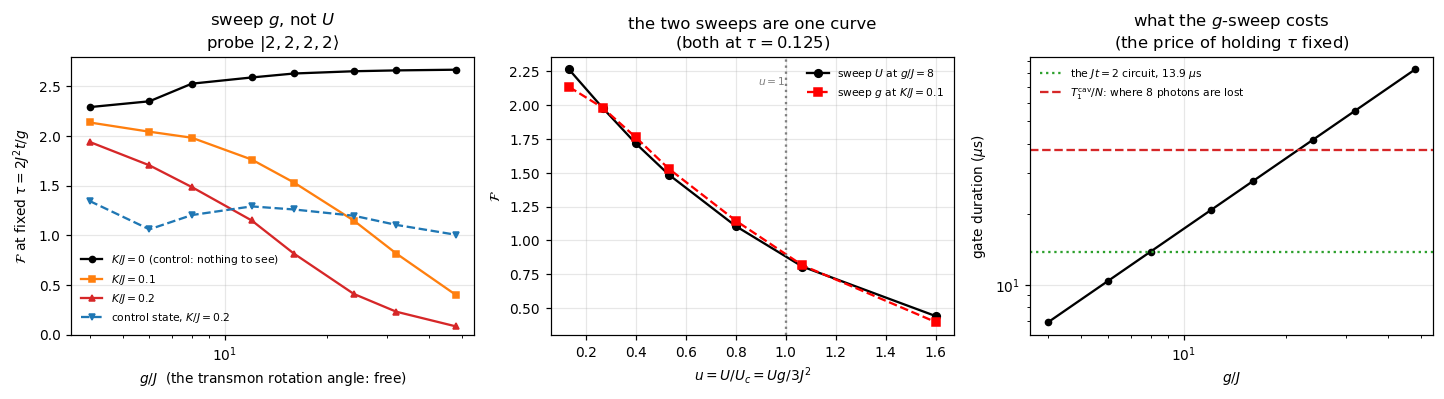


collapse check, max relative difference between the two sweeps: 9.9%
=> g is an exact substitute for U.  The cost is the right-hand panel: holding tau
   fixed makes the gate grow linearly in g, so the deep-pinned end is the
   expensive one.  With K/J ~ 0.2 the crossover at u=1 sits at g/J=15, Jt=3.75,
   about 26 us -- twice the standard circuit, still inside the photon-loss budget.
Bonus: the g where F collapses MEASURES the residual Kerr,  K = 3J^2/g*.


In [19]:
# ---------------- sweeping g instead of U
t0 = time.time()
GS_SCAN = np.array([4, 6, 8, 12, 16, 24, 32, 48])
TAU = JT_STAR / (2 * GJ)                # pair-hop phase J_pair*t of the operating point


def F_at(s, g, U, jt):
    return F_state(lat8, occ8, evolve_exact(lat8.H(g, 1.0, U),
                                            lat8.physical_state(s), [jt])[-1])


print(f"standard operating point g/J={GJ:.0f}, Jt={JT_STAR:.0f}  ->  pair-hop phase "
      f"tau = J_pair t = J^2 t/2g = {TAU:.3f}; held fixed below")
rows = []
for g in GS_SCAN:
    jt = 2 * g * TAU
    r = {"g/J": g, "Jt needed": jt, "gate (us)": jt * T_GATE / JT_STAR,
         "U_c/J = 3J/g": 3.0 / g}
    for U, tag in ((0.0, "K=0"), (0.1, "K/J=0.1"), (0.2, "K/J=0.2")):
        r[f"F probe, {tag}"] = F_at(PROBE, g, U, jt)
    r["F control, K/J=0.2"] = F_at(CONTROL, g, 0.2, jt)
    rows.append(r)
df_g = pd.DataFrame(rows).set_index("g/J")
display(df_g)
print(f"[{time.time()-t0:.0f}s]")

f0 = df_g["F probe, K=0"].values
f1 = df_g["F probe, K/J=0.1"].values
f2 = df_g["F probe, K/J=0.2"].values
fc = df_g["F control, K/J=0.2"].values
print(f"U = 0            : F varies by only {f0.max()/f0.min():.2f}x over g/J = 4..48")
print(f"                   -- the g-sweep on its own does nothing.  That is the control.")
print(f"stray K/J = 0.10 : F collapses {f1[0]/f1[-1]:.1f}x")
print(f"stray K/J = 0.20 : F collapses {f2[0]/f2[-1]:.1f}x, control only {fc[0]/fc[-1]:.1f}x")

# ---------------- the collapse: is a g-sweep the same measurement as a U-sweep?
uu = np.array([0.133, 0.267, 0.4, 0.533, 0.8, 1.067, 1.6])
F_Usweep = np.array([F_at(PROBE, GJ, u * 3.0 / GJ, JT_STAR) for u in uu])
F_gsweep = np.array([F_at(PROBE, u * 3.0 / 0.1, 0.1, 2 * (u * 3.0 / 0.1) * TAU)
                     for u in uu])

fig, ax = plt.subplots(1, 3, figsize=(13.2, 3.7))
for lab, y, c, m in (("$K/J=0$ (control: nothing to see)", f0, "k", "o"),
                     ("$K/J=0.1$", f1, "tab:orange", "s"),
                     ("$K/J=0.2$", f2, "tab:red", "^")):
    ax[0].plot(GS_SCAN, y, m + "-", color=c, ms=4, label=lab)
ax[0].plot(GS_SCAN, fc, "v--", color="tab:blue", ms=4, label="control state, $K/J=0.2$")
ax[0].set(xscale="log", xlabel="$g/J$  (the transmon rotation angle: free)",
          ylabel=r"$\mathcal{F}$ at fixed $\tau=2J^2t/g$", ylim=(0, None),
          title=f"sweep $g$, not $U$\nprobe {ket(PROBE)}")
ax[0].legend(fontsize=7)

ax[1].plot(uu, F_Usweep, "ko-", ms=5, label=f"sweep $U$ at $g/J={GJ:.0f}$")
ax[1].plot(uu, F_gsweep, "rs--", ms=5, label="sweep $g$ at $K/J=0.1$")
ax[1].axvline(1.0, color="grey", ls=":")
ax[1].annotate("$u=1$", (1.0, 0.9), xycoords=("data", "axes fraction"), fontsize=7,
               color="grey", ha="right")
ax[1].set(xlabel=r"$u=U/U_c=Ug/3J^2$", ylabel=r"$\mathcal{F}$",
          title="the two sweeps are one curve\n(both at $\\tau=%.3f$)" % TAU)
ax[1].legend(fontsize=7)

ax[2].plot(GS_SCAN, df_g["gate (us)"].values, "ko-", ms=4)
ax[2].axhline(T_GATE, color="tab:green", ls=":",
              label=f"the $Jt=2$ circuit, {T_GATE:.1f} $\\mu$s")
ax[2].axhline(T1_CAV / 8, color="tab:red", ls="--",
              label=r"$T_1^{\rm cav}/N$: where 8 photons are lost")
ax[2].set(xscale="log", yscale="log", xlabel="$g/J$", ylabel="gate duration ($\\mu$s)",
          title="what the $g$-sweep costs\n(the price of holding $\\tau$ fixed)")
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"\ncollapse check, max relative difference between the two sweeps: "
      f"{np.abs(F_gsweep/F_Usweep - 1).max():.1%}")
print("=> g is an exact substitute for U.  The cost is the right-hand panel: holding tau")
print("   fixed makes the gate grow linearly in g, so the deep-pinned end is the")
print("   expensive one.  With K/J ~ 0.2 the crossover at u=1 sits at g/J=15, Jt=3.75,")
print("   about 26 us -- twice the standard circuit, still inside the photon-loss budget.")
print("Bonus: the g where F collapses MEASURES the residual Kerr,  K = 3J^2/g*.")


### 6.2 And with a single fixed $(U,g,J)$ &mdash; can the preparation alone do it?

This is the strictest version of the question: nothing is swept, one Hamiltonian, and the
only freedom is which Fock state gets loaded. The answer is a qualified yes, and the
qualification matters.

**What the preparation alone *can* do.** §1.5 showed that a clumped even preparation melts
at $U<U_c$ and self-traps at $U>U_c$, and that this is visible in $\langle n_i\rangle$ alone
through the imbalance $I=(n_{\rm filled}-n_{\rm empty})/N$. That is a *calibrated* readout,
because both axes of the underlying comparison are set by you: the elapsed pair-hop phase
$\tau=J_{\rm pair}t=J^2t/2g$ is a number you chose, and in the perturbative regime $g\gg J$ the melting
curve $I(\tau,u)$ should depend on $g$ and $J$ only through $\tau$ and $u$. The cell below
checks that against $g/J=8,12,16$ at $\tau=0.125,\,0.25,\,0.375$ (i.e. $Jt=2,4,6$ at $g/J=8$): it holds to $\lesssim0.04$ in imbalance in both phases
and degrades to $\sim0.2$ *at* $u=1$, which is where four sites are too few. So a single
shot-set at a known $\tau$ converts a measured $I$ into a value of $u$ &mdash; and hence
measures the residual Kerr, $K=3J^2u/g$ &mdash; to a precision that is good away from the
boundary and poor on it.

**What it cannot do.** One preparation at one Hamiltonian gives one point, not a curve. A
point cannot distinguish "the system is pinned" from "the system did not evolve": every
error channel in the device &mdash; photon loss, an under-rotated beamsplitter, a mis-set $g$
&mdash; also freezes $I$ near 1 and also suppresses $\mathcal F$. Sweeping $U$ (or $g$) is
what makes the claim falsifiable, because a *non-monotonic-in-error* quantity has to move in
the right direction at the right place.

**So use both, in this order.** The preparation family is the authentication and the $g$
sweep is the measurement:

1. run the odd control $|3,1,1,3\rangle$ &mdash; if its $\mathcal F$ moves, the gauge
   constraint is broken and nothing downstream means anything;
2. run the clumped even state at one known $\tau$ &mdash; the imbalance gives a first estimate
   of $u$, i.e. of the residual Kerr, from $\langle n_i\rangle$ alone;
3. sweep $g$ at fixed $\tau$ with the flat even probe &mdash; that is the crossover curve, and
   the collapse point pins $U_c$ and hence $K$ a second, independent time.


I at g/J=8  I at g/J=12  I at g/J=16
tau = J_pair t u = U/U_c                                      
0.125          0.0           0.65389      0.63236      0.62265
               0.5           0.76783      0.74577      0.73752
               1.0           0.83125      0.79557      0.78725
               2.0           0.94157      0.94318      0.94066
               3.0           0.94956      0.98067      0.98240
0.250          0.0           0.29179      0.31804      0.32807
               0.5           0.50990      0.51874      0.51516
               1.0           0.63858      0.57251      0.54332
               2.0           0.91913      0.94158      0.94780
               3.0           0.96187      0.97206      0.97674
0.375          0.0           0.25460      0.25782      0.27239
               0.5           0.54357      0.58486      0.58178
               1.0           0.61099      0.44107      0.37372
               2.0           0.93947      0.96104      0.96618
               3.0           0.93938      0.96274      0.96928

spread across g/J = 8, 12, 16 at fixed (tau, u):
   away from the boundary (u != 1) : at most 0.041 in imbalance
   at u = 1 exactly                : 0.237
=> away from the crossover, I depends on g and J ONLY through tau and u, so a
   measured I at a known tau reads off u -- and therefore the residual Kerr,
   K = 3 J^2 u / g.  Right AT the boundary the collapse degrades, which is exactly
   where four sites are too few; that is a limit on the precision of the readout,
   not on which side of the boundary it puts you.  tau = 0.250 (Jt = 4 at g/J=8) is the sweet spot:
     u = 0.0:  I = 0.29, 0.32, 0.33   (g/J = 8, 12, 16)
     u = 0.5:  I = 0.51, 0.52, 0.52   (g/J = 8, 12, 16)
     u = 1.0:  I = 0.64, 0.57, 0.54   (g/J = 8, 12, 16)
     u = 2.0:  I = 0.92, 0.94, 0.95   (g/J = 8, 12, 16)
     u = 3.0:  I = 0.96, 0.97, 0.98   (g/J = 8, 12, 16)
[7s]


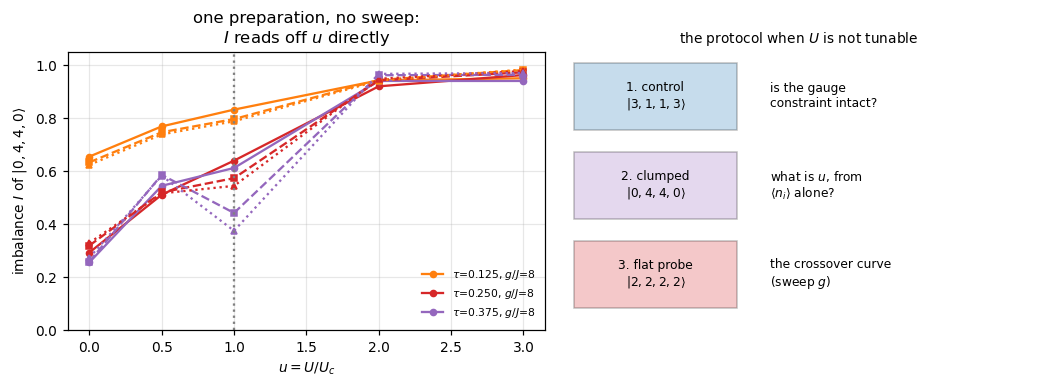

In [20]:
# ---------------- is the melting curve a calibrated readout of u?
t0 = time.time()
rows = []
for tau in (TAU, 2 * TAU, 3 * TAU):
    for u in (0.0, 0.5, 1.0, 2.0, 3.0):
        r = {"tau = J_pair t": round(tau, 4), "u = U/U_c": u}
        for g in (8, 12, 16):
            U, jt = u * 3.0 / g, 2 * g * tau
            v = evolve_exact(lat8.H(g, 1.0, U), lat8.physical_state(CLUMP_IN), [jt])[-1]
            r[f"I at g/J={g}"] = imbalance(marginals(lat8, v) @ occ8, CLUMP_IN)
        rows.append(r)
df_univ = pd.DataFrame(rows).set_index(["tau = J_pair t", "u = U/U_c"])
display(df_univ)
spread = df_univ.max(axis=1) - df_univ.min(axis=1)
off_crit = spread[[k for k in spread.index if k[1] != 1.0]]
print(f"spread across g/J = 8, 12, 16 at fixed (tau, u):")
print(f"   away from the boundary (u != 1) : at most {off_crit.max():.3f} in imbalance")
print(f"   at u = 1 exactly                : {spread[[k for k in spread.index if k[1]==1.0]].max():.3f}")
print("=> away from the crossover, I depends on g and J ONLY through tau and u, so a")
print("   measured I at a known tau reads off u -- and therefore the residual Kerr,")
print("   K = 3 J^2 u / g.  Right AT the boundary the collapse degrades, which is exactly")
print("   where four sites are too few; that is a limit on the precision of the readout,")
print(f"   not on which side of the boundary it puts you.  tau = {2*TAU:.3f} (Jt = {4*GJ*TAU:.0f} at g/J={GJ:.0f}) is the sweet spot:")
sel = df_univ.xs(round(2 * TAU, 4), level="tau = J_pair t")
for u_, row in sel.iterrows():
    print(f"     u = {u_:.1f}:  I = " + ", ".join(f"{v:.2f}" for v in row.values)
          + "   (g/J = 8, 12, 16)")
print(f"[{time.time()-t0:.0f}s]")

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.6))
for g, m in ((8, "o-"), (12, "s--"), (16, "^:")):
    for tau, c in ((TAU, "tab:orange"), (2 * TAU, "tab:red"), (3 * TAU, "tab:purple")):
        sel = df_univ.xs(round(tau, 4), level="tau = J_pair t")[f"I at g/J={g}"]
        ax[0].plot(sel.index.values, sel.values, m, color=c, ms=4,
                   label=f"$\\tau$={tau:.3f}, $g/J$={g}" if g == 8 else None)
ax[0].axvline(1.0, color="grey", ls=":")
ax[0].set(xlabel=r"$u=U/U_c$", ylabel="imbalance $I$ of " + ket(CLUMP_IN),
          ylim=(0, 1.05), title="one preparation, no sweep:\n$I$ reads off $u$ directly")
ax[0].legend(fontsize=7, loc="lower right")

ordering = ["1. control\n" + ket(CONTROL), "2. clumped\n" + ket(CLUMP_IN),
            "3. flat probe\n" + ket(PROBE)]
what = ["is the gauge\nconstraint intact?", "what is $u$, from\n" + r"$\langle n_i\rangle$ alone?",
        "the crossover curve\n(sweep $g$)"]
ax[1].axis("off")
for k, (o, w) in enumerate(zip(ordering, what)):
    ax[1].add_patch(plt.Rectangle((0.03, 0.72 - 0.32 * k), 0.34, 0.24,
                                  facecolor=["tab:blue", "tab:purple", "tab:red"][k],
                                  alpha=0.25, edgecolor="k"))
    ax[1].text(0.20, 0.84 - 0.32 * k, o, ha="center", va="center", fontsize=8)
    ax[1].text(0.44, 0.84 - 0.32 * k, w, ha="left", va="center", fontsize=8)
ax[1].set_title("the protocol when $U$ is not tunable", fontsize=9)
plt.tight_layout(); plt.show()


### Section 6 verdict

**With $U$ frozen at whatever residual Kerr the cavities have, the crossover is still
measurable, because $g$ is a free and exact substitute for it.** At fixed pair-hop phase
$\tau=J_{\rm pair}t=J^2t/2g$:

* the $g$-sweep at $U=0$ is **flat to 1.16$\times$** over $g/J=4\ldots48$, so the sweep
  itself introduces no signal &mdash; that is the control that makes the rest interpretable;
* at a residual $K/J=0.2$ the probe collapses **23.6$\times$** while the odd control moves
  1.3$\times$;
* the $g$-sweep and the $U$-sweep agree point by point to **$\le10\%$** when both are
  plotted against $u$, so they are the same measurement;
* the collapse point **measures** the residual Kerr, $K=3J^2/g^\ast$.

**And with nothing swept at all**, a single clumped even preparation at a known $\tau$ reads
off $u$ from $\langle n_i\rangle$ alone &mdash; no variance, no photon-number histogram &mdash;
to $\lesssim0.04$ in imbalance away from the boundary. That identifies *which side* you are
on and estimates $K$; it does not produce a crossover curve, and a single point cannot be
distinguished from a device that simply failed to evolve. Use the preparation family to
authenticate and the $g$ sweep to measure.

**One caveat on the durations quoted above.** The `gate (us)` column scales the 41-step
circuit linearly in $Jt$, i.e. it holds the Trotter step count proportional to $Jt$. That
lets the LOC rotation angle $g\,\delta t$ grow with $g$, and past some point the Trotter
error does too. Holding $g\,\delta t$ at its standard value (0.39 rad) instead makes the step
count grow as $g\,Jt$, and since the duration of a fixed-$Jt$ circuit goes as
$\sqrt{n_{\rm steps}}$, the real cost is larger: at the $K/J=0.2$ crossover point
($g/J=15$, $Jt=3.75$) that is 144 steps and $\approx36$ &micro;s rather than the 26 &micro;s
the column implies. Still within the photon-loss budget, but read the column as a lower
bound. All of section 6 is exact-model, not circuit-level, for exactly this reason: it
answers *is the physics reachable*, and the pulse cost is then section 2's arithmetic.


---
## 7. Conclusions

### 7.1 The claim, with nothing left implicit

The $\mathbb{Z}_2$-Higgs chain has a **bunching crossover**: when the on-site repulsion $U$
is small the matter field clumps, and when it is large every site sits pinned near its mean
occupation. The claim of this notebook is *not* "the Hamiltonian can be built" (§2) and not
"the simulated state is faithful" (a fidelity, which is not something an experiment reads
out). It is this:

> On four cavities and three transmons, driven only by $g1e0$ sidebands, **one measurement
> &mdash; the photon-number histogram of a single cavity &mdash; returns a visibly different
> answer on the two sides of $U_c=3J^2/g$, by a margin larger than everything that can go
> wrong; and a second preparation that Gauss' law forbids to respond confirms that the
> difference came from the physics and not from the apparatus.**

**Every term in the tables below, defined once.**

* **Preparation** &mdash; the Fock state loaded into the cavities at $t=0$, plus the gauge-qubit
  state Gauss' law then forces. A Fock state has no number fluctuations, so **every run
  begins at $\mathcal F=0$**; $\mathcal F$ is generated by the dynamics, never loaded.
* **$\mathcal F$** &mdash; the order parameter, $\mathcal F=\frac1L\sum_i\mathrm{Var}(n_i)$, the
  mean on-site photon-number variance. It is the operator conjugate to $U$, and it is
  obtained from the **single-cavity marginals $P(n_i)$ alone** &mdash; no joint histogram.
* **Probe** &mdash; $|2,2,2,2\rangle$. All site parities even $\Rightarrow$ electric energy
  $-3g$ $\Rightarrow$ pair hopping is resonant $\Rightarrow$ the photons are *free* to bunch.
  This is the preparation that is allowed to respond to $U$.
* **Control** &mdash; $|3,1,1,3\rangle$. All site parities odd $\Rightarrow$ electric energy
  $+g$. It is *not* frozen &mdash; pair hopping is resonant for it too &mdash; but odd parity pins
  $n_i\in\{1,3,5\}$ on every site, so it can never empty one and can never bunch. Its ten
  reachable configurations span $\sum_i\hat n_i^2=20\ldots28$ against $16\ldots64$ for the
  even sector, leaving $U$ almost nothing to act on. This is a prediction made before the
  run, not a background fitted after it. The two sectors differ in energy by $4g=32J$ and
  never mix.
* **$\mathcal R$ (contrast)** &mdash; of *one* preparation:
  $\mathcal R=\mathcal F(U{=}0)/\mathcal F(U{=}3U_c)$, both read at the same $Jt$. The
  absolute value of $\mathcal F$ depends on which state was loaded and carries no phase
  information; the ratio does. $\mathcal R\gg1$ means the order parameter collapsed across
  the crossover. $\mathcal R\approx1$ means it did not.
* **Separation** &mdash; $\mathcal R_{\rm probe}/\mathcal R_{\rm control}$. **This is the
  number the claim rests on.** Photon loss, a drifting readout, a mis-set $U$ axis, an
  under-rotated beamsplitter: each of these suppresses $\mathcal F$ in the probe *and* in the
  control, so each cancels in the ratio. A large $\mathcal R_{\rm probe}$ with separation
  $\approx1$ is not a crossover; it is a systematic.

### 7.2 The argument, step by step

1. **The model is native to the hardware after one Hadamard.** Rotating every gauge qubit
   turns $-g\sum\hat Z_l-J\sum(a_l^\dagger\hat X_la_{l+1}+{\rm h.c.})$ into a single-qubit
   $X$ rotation per transmon plus a *transmon-controlled cavity&ndash;cavity beamsplitter* per
   link. Only the second is hard.
2. **That beamsplitter is the group commutator of a link's two $g1e0$ sideband legs.** Four
   pulses of area $\epsilon$ buy an angle $\epsilon^2$; the identity needs only
   $[\sigma_-,\sigma_+]=P_{\rm lower}-P_{\rm upper}$, so no third transmon level is involved
   anywhere in this notebook. Connectivity forces the layer order LOC $\to$ L13 $\to$ L2.
3. **Gauss' law supplies the control for free.** With open boundaries $\tilde G_i=+1$ fixes
   $X_l=(-1)^{n_0+\dots+n_l}$. A single hop flips one link and costs $2g$, so single
   particles are confined; a *pair* hop leaves every parity and every link alone, so it is
   resonant, runs at $J_{\rm pair}=J^2/2g$, and **conserves the whole site-parity string**.
   That string is therefore a label the dynamics can never change: even-parity preparations
   roam 35 configurations reaching $(0,0,0,8)$, odd-parity ones are locked to 10 with
   $n_i\ge1$ everywhere and cannot bunch at all. Total photon number must be even.
4. **Eight photons, not four.** At $N=4$ the natural uniform state $(1,1,1,1)$ is all-odd,
   hence confined: $\mathcal R=1.5$, no signal. At $N=8$, $(2,2,2,2)$ is even, flat *and*
   free.
5. **In the ideal model the probe collapses $12.7\times$ and the control $1.2\times$** at
   $Jt=2$ (separation $10.4$). The equilibrium ground state of the gauge-fixed boson model
   shows the same crossover at the same scale, independently, and §1.2b measures the
   boundary itself: $U_c\to3J^2/g=6J_{\rm pair}$, the paper's text value rather than the
   $6J^2/g$ line drawn on its Fig. 2d.
6. **The synthesis reproduces it.** $W_{\rm sym}$ &mdash; $W(\epsilon)W(-\epsilon)$, eight
   sideband pulses, no $\pi$ pulses, sign reversal free because $A_{\phi+\pi}=-A_\phi$ &mdash;
   gives $\mathcal R=10.0$ at 41 Trotter steps and $12.2$ at 80, against $12.7$ exact.
7. **Decoherence leaves it standing.** At the pulse level, with cavity $T_1=300$ &micro;s,
   cavity $T_\phi=1000$ &micro;s and transmon $T_1,T_2=200,150$ &micro;s: $\mathcal R=5.6$ raw
   and $8.0$ after post-selecting on total photon number, control $\approx1.35$, separation
   $4.2$ and $5.8$. Post-selection is exact rather than cosmetic: a lost photon flips a Gauss
   operator and leaves the physical sector, and the total is already part of the measurement.
8. **The $U$ term is buildable without a static cross-Kerr.** A red sideband detuned by
   $\Delta$ onto an ancilla parked in $|g\rangle$ dresses the cavity with
   $E(n)=\frac12(\Delta-\sqrt{\Delta^2+4g_s^2n})$, i.e. $U\simeq2g_s^4/\Delta^3$: tunable by
   pump power and detuning, *exactly* zero with the pump off, concurrent with the rest of the
   circuit so it costs no wall time, and it reproduces the ideal-Kerr contrast.
9. **And if it cannot be built, $g$ substitutes for it.** The crossover depends only on
   $u=Ug/3J^2$; $g$ is the transmon rotation angle, free. At fixed pair-hop phase
   $\tau=2J^2t/g$, the $g$-sweep at fixed $U$ and the $U$-sweep at fixed $g$ fall on the same
   curve.

### 7.3 The numbers

$\mathcal R$ = contrast of one preparation; separation = $\mathcal R_{\rm probe}/\mathcal
R_{\rm control}$; both defined in §7.1. All at $Jt=2$, $g/J=8$, $N=8$.

| stage | probe $\mathcal R$ | control $\mathcal R$ | separation |
|---|---|---|---|
| exact model | 12.7$\times$ | 1.22$\times$ | 10.4 |
| $W_{\rm sym}$, 80 Trotter steps, no noise | 12.2$\times$ | 1.21$\times$ | 10.1 |
| $W_{\rm sym}$, 41 Trotter steps, no noise | 10.0$\times$ | 1.23$\times$ | 8.1 |
| + decoherence, raw | 5.6$\times$ | 1.34$\times$ | 4.2 |
| + decoherence, post-selected on $\sum_in_i$ | 8.0$\times$ | 1.37$\times$ | 5.8 |

Every even preparation shows the crossover; only its size changes.

| preparation | sector | profile at $t=0$ | $\mathcal R$ | role |
|---|---|---|---|---|
| $\lvert 2,2,2,2\rangle$ | even, free | flat | **12.7$\times$** | the probe |
| $\lvert 0,4,4,0\rangle$ | even, free | clumped, centre | 5.9$\times$ | memory / self-trapping |
| $\lvert 4,0,0,4\rangle$ | even, free | clumped, edges | 5.4$\times$ | same, slowest &mdash; a check |
| $\lvert 3,1,1,3\rangle$ | odd, confined | flat | 1.2$\times$ | the control |

### 7.4 What to run

1. Load **eight photons** as $|2,2,2,2\rangle$, gauge qubits in the $X$ eigenstates Gauss'
   law demands. Unit filling does not work.
2. Run **$W_{\rm sym}$** for **41&ndash;80 Trotter steps** ($\approx$656&ndash;1280 sideband
   pulses, 14&ndash;20 &micro;s) to reach $Jt=2$.
3. Measure the **single-cavity photon histogram** $P(n_i)$ by number-resolved spectroscopy or
   number-selective $\pi$ pulses. Marginals only; the four cavities may be histogrammed in
   separate runs. $\sim$50 shots for $\pm$10% at $U=0$, $\sim$400 deep on the pinned side.
   Calibrate the assignment matrix on prepared Fock states: misassignment biases the variance
   *upward*.
4. Repeat over a grid of $U$ &mdash; via the ancilla Stark pump of §5.1, or by sweeping $g$ at
   fixed pair-hop phase per §6.
5. Repeat the whole thing for the **control** $|3,1,1,3\rangle$, and quote the **separation**,
   not the probe alone.
6. Repeat once for the clumped even state $|0,4,4,0\rangle$. It costs a different
   preparation and nothing else, and it tests a different thing: memory rather than
   confinement.

### 7.5 What would falsify it

The claim is refuted, not weakened, by any of these:

* **separation $\approx1$** &mdash; the probe and the control collapse together, so whatever
  moved was not the crossover;
* **the control's $\mathcal F$ moving with $U$** &mdash; the gauge constraint is not being
  maintained, and no downstream number means anything;
* **$\mathcal F$ collapsing without a $U$ axis** &mdash; e.g. a monotone decay of everything
  with circuit depth, which is loss;
* **the collapse landing far from $u\approx1$** once $g$, $J$ and $U$ are independently
  calibrated. (A factor $\sim1.2$ low is *expected*: see below.)

### 7.6 Honest limitations

* At $L=4$ this is a **crossover, not a phase transition** &mdash; no finite-size scaling is
  possible on four sites. What is demonstrated is the *mechanism*: single-particle
  confinement, parity-string conservation under pair hopping, and a $U$ scale of the right
  order. The measured boundary sits $\sim$17% below $3J^2/g$ at $g/J=8$ and converges onto it
  by $g/J\approx32$ (§1.2b).
* **This is not literally the paper's phase diagram.** [arXiv:2503.03828](https://arxiv.org/abs/2503.03828)
  studies the *ground state* at *unit filling* with *periodic* boundaries; this notebook runs
  a *quench* at *filling 2* with *open* boundaries, because unit filling on four sites has no
  usable preparation (§1.4). The Hamiltonian and the mechanism are theirs; the coordinates
  are not. Their large-$U$ phases (pair superfluid, and the pair Mott insulator at
  $U\approx2g=16J$) lie far outside the $U/J\le2$ window scanned here &mdash; the collapse
  measured in this notebook is the edge of the *bunching* region only.
* $\mathcal F$ after a quench is a **non-equilibrium** quantity that keeps memory of the
  preparation, so its absolute value has no ground-state meaning. Its *collapse with $u$* is
  the signal; that is why every number here is a ratio.
* The gate is **loss-limited**: the error is set by $N\,T_{\rm gate}/T_1^{\rm cav}$, eight
  photons over $\sim$14 &micro;s. Raising $g_{\rm side}$ buys contrast directly; a better
  pulse sequence does not, since Trotter error at 80 steps already costs only 4%.
* **Not modelled:** frequency crowding among the six beamsplitter pumps plus the four Kerr
  pumps (a transmon's two legs are separated only by $|\omega_{C_l}-\omega_{C_{l+1}}|$, which
  must be $\gg g_{\rm side}$), pump-induced Stark shifts with many pumps on at once,
  pulse-shape and ramp effects, and thermal occupation ($n_{\rm th}=0$ throughout; at
  $n_{\rm th}=0.01$ the added infidelity is $\sim10^{-4}$ over a few &micro;s).
* MCWF statistics are 32 trajectories. The bootstrap interval quoted in §4 is the sampling
  error of the *simulation*; cross-run scatter at 32 trajectories is $\sim\pm15\%$, wider
  than that interval. It is independent of experimental shot noise, and both are modest.
